# **2. Motivos de Cartão e Detecção de VAR: Embeddings, BERTopic e Rotulagem Semântica**

Este notebook implementa um pipeline NLP para analisar as justificativas livres de cartões amarelos e vermelhos e os motivos de acréscimos nas súmulas do Campeonato Brasileiro.

**Cartões:** identificar o *tipo de falta* por trás de cada cartão, caracterizando o perfil de marcação de cada árbitro e o padrão de infrações de cada time.

**Acréscimos/atrasos:** detectar, de forma binária, se há menção ao VAR na justificativa registrada pelo árbitro.

## Pipeline de Motivos de Cartão

1. **Embeddings base** — `multilingual-e5-large` (1024 dim) aplicado ao conjunto de textos únicos de justificativas, com prefixos `passage:` / `query:` conforme protocolo E5.
2. **Seleção de hiperparâmetros** — grid search sobre `n_neighbors` (UMAP) e `min_topic_size` (HDBSCAN) via Silhouette Score.
3. **BERTopic — Passagem 1** — clustering exploratório com o modelo base; gera pares positivos para o fine-tuning.
4. **Fine-tuning** — `MultipleNegativesRankingLoss` com pares derivados dos clusters da Passagem 1 (*self-supervised contrastive learning*, Gao et al. 2021).
5. **BERTopic — Passagem 2** — clusters finais com embeddings do modelo fine-tunado.
6. **Ablação** — comparação Pass 1 vs. Pass 2 em número de clusters, taxa de outliers e Silhouette Score.
7. **Rotulagem semântica manual** — taxonomia fixa, mapeamento manual dos 102 clusters e mapeamento manual dos outliers HDBSCAN.
8. **Diagnóstico de representatividade** — score por texto via similaridade cosseno contra o centroide ponderado do grupo.

---


## **1. Bibliotecas**

- `sentence-transformers` — embeddings semânticos e fine-tuning com `MultipleNegativesRankingLoss`
- `bertopic` — clustering temático via UMAP + HDBSCAN + c-TF-IDF
- `umap-learn` — redução de dimensionalidade antes do HDBSCAN
- `scikit-learn` — Silhouette Score como métrica de qualidade de clustering


In [259]:
import re
import shutil
import unicodedata
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from bertopic import BERTopic
from matplotlib.colors import LinearSegmentedColormap
from sentence_transformers import SentenceTransformer
from sentence_transformers import models as st_models
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 220)
plt.style.use("default")
plt.rcParams.update({
    "axes.grid": False,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "axes.labelweight": "bold",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "legend.title_fontsize": 12,
    "font.size": 12,
})


## **2. Configuração**

Caminhos, hiperparâmetros e flags de execução. O modelo fine-tunado é reutilizado quando já existe em `models/`, evitando re-treinar em execuções subsequentes.

| Parâmetro | Valor | Descrição |
|-----------|-------|-----------|
| `MODEL_NAME` | `intfloat/multilingual-e5-large` | Modelo de embeddings — multilingual, 1024 dim |
| `MODEL_NAME_BASELINE` | `paraphrase-multilingual-mpnet-base-v2` | Modelo anterior (768 dim), mantido como referência de ablação |
| `ENCODE_PREFIX_PASSAGE` | `"passage: "` | Prefixo obrigatório para passagens no protocolo E5 |
| `ENCODE_PREFIX_QUERY` | `"query: "` | Prefixo obrigatório para consultas no protocolo E5 |
| `FINETUNE_EPOCHS` | 1 | Uma epoch evita overfitting com pares sintéticos em corpus pequeno |
| `BERTOPIC_NGRAM_RANGE` | (1, 3) | Captura expressões como "falta tática" e "ataque promissor" |
| `REPRESENTATIVENESS_MIN_SCORE` | 0.70 | Corte inicial para texto pouco central no grupo |
| `REPRESENTATIVENESS_MIN_MARGIN` | 0.05 | Corte inicial para texto próximo de outro grupo |

A rotulagem manual fica em `data/processed/semantic_reasons/card_reasons/`:

- `card_reason_group_taxonomy.csv`
- `card_reason_manual_cluster_labels.csv`
- `card_reason_manual_outlier_labels.csv`


In [260]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
PROCESSED_PATH = DATA_PATH / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
VIZ_PATH = PROJECT_ROOT / "viz"
OUTPUT_DIR = PROCESSED_PATH / "semantic_reasons"
CARD_OUTPUT_DIR = OUTPUT_DIR / "card_reasons"
DELAY_OUTPUT_DIR = OUTPUT_DIR / "delay_reasons"

CARD_REASONS_PATH = PROCESSED_PATH / "card_reasons.csv"
DELAY_REASONS_PATH = PROCESSED_PATH / "delay_reasons.csv"

for directory in [MODELS_DIR, OUTPUT_DIR, CARD_OUTPUT_DIR, DELAY_OUTPUT_DIR, VIZ_PATH]:
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

MODEL_NAME_BASELINE = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
MODEL_NAME          = "intfloat/multilingual-e5-large"
FINETUNED_MODEL_DIR = MODELS_DIR / "football_card_reason_e5_large_two_pass"
ENCODE_PREFIX_PASSAGE = "passage: "
ENCODE_PREFIX_QUERY   = "query: "

RUN_FINE_TUNING = True
RETRAIN_FINETUNED_MODEL = False
USE_FINETUNED_IF_AVAILABLE = True
FINETUNE_EPOCHS = 1
FINETUNE_BATCH_SIZE = 32
MAX_TEXTS_PER_GROUP_FOR_FINETUNE = 220
MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE = 450

CARD_MIN_TOPIC_SIZE = 45
DELAY_MIN_TOPIC_SIZE = 35
BERTOPIC_NGRAM_RANGE = (1, 3)

CARD_TEXT_COLUMN = "card_reason_text"
CARD_TEXT_KEY_COLUMN = "card_reason_text_key"
DELAY_TEXT_COLUMN = "delay_reason_clean"

TOP_N_CARD_TEXTS = 10
TOP_N_TEAMS = 10
TOP_N_REFEREES = 10
REPRESENTATIVENESS_MIN_SCORE = 0.70
REPRESENTATIVENESS_MIN_MARGIN = 0.05

PLOT_BLUE = "#3D79F3"
PLOT_RED = "#E6352F"
PLOT_YELLOW = "#F8DE02"
PLOT_PALETTE = [
    "#3D79F3", "#E6352F", "#F9B90A", "#34A74B", "#A1D8B6", "#D2C48E",
    "#F9AE8D", "#80B9CE", "#C8D0D0", "#909090", "#7888C8", "#F8DE02",
    "#803850", "#2C7AA1", "#FD90AA", "#E191FC", "#94E8FD", "#4D494A",
]
PLOT_CARD_COLORS = {"yellow": PLOT_YELLOW, "red": PLOT_RED}
PLOT_HEATMAP_GREEN = LinearSegmentedColormap.from_list("plot_heatmap_green", ["#C8D0D0", "#A1D8B6", "#34A74B"])
PLOT_HEATMAP_BLUE = LinearSegmentedColormap.from_list("plot_heatmap_blue", ["#C8D0D0", "#80B9CE", "#3D79F3"])


def plot_colors(values) -> list[str]:
    if isinstance(values, int):
        return [PLOT_PALETTE[i % len(PLOT_PALETTE)] for i in range(values)]
    color_map = globals().get("CARD_GROUP_COLOR_MAP", {})
    return [color_map.get(value, PLOT_PALETTE[i % len(PLOT_PALETTE)]) for i, value in enumerate(values)]


def group_legend_handles(groups) -> list:
    from matplotlib.patches import Patch
    return [Patch(facecolor=CARD_GROUP_COLOR_MAP.get(group, PLOT_BLUE), edgecolor="black", linewidth=0.6, label=group) for group in groups]


def save_plot(fig, filename: str) -> None:
    fig.savefig(VIZ_PATH / filename, dpi=300, bbox_inches="tight")


def style_axis(ax, title: str | None = None, xlabel: str | None = None, ylabel: str | None = None, x_rotation: int = 0) -> None:
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(0.8)
    ax.tick_params(axis="both", colors="black", width=0.8, length=4, pad=7)
    ax.tick_params(axis="x", labelrotation=x_rotation)
    if title is not None:
        ax.set_title(title, fontweight="bold", pad=16)
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontweight="bold", labelpad=14)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontweight="bold", labelpad=14)


def style_patches(ax) -> None:
    for patch in ax.patches:
        patch.set_edgecolor("black")
        patch.set_linewidth(0.6)


def style_lines(ax) -> None:
    for line in ax.lines:
        line.set_linewidth(2)
        line.set_markeredgecolor("black")
        line.set_markeredgewidth(0.7)


def style_legend(ax, title: str | None = None, loc: str = "upper left", bbox_to_anchor: tuple[float, float] = (1.04, 1), ncol: int = 1) -> None:
    legend = ax.legend(title=title, loc=loc, bbox_to_anchor=bbox_to_anchor, ncol=ncol, frameon=False, borderaxespad=1.2, labelspacing=0.8, handlelength=1.6)
    if legend is not None and legend.get_title() is not None:
        legend.get_title().set_fontweight("bold")


def style_colorbar(colorbar) -> None:
    colorbar.outline.set_edgecolor("black")
    colorbar.outline.set_linewidth(0.6)
    colorbar.ax.tick_params(colors="black", width=0.8, length=3, pad=6)


## **3. Carregamento e Pré-processamento dos Dados**

Os dois arquivos de entrada são gerados no notebook 1. Para cartões, o texto de justificativa (`card_reason_text`) passa por normalização Unicode e remoção de pontuação — necessário para reduzir a fragmentação no vocabulário do BERTopic e para que variações ortográficas como "calçar" e "calcar" gerem embeddings próximos. Para atrasos, o campo `delay_reason` é mantido em forma original para análise léxica posterior.


In [261]:
REQUIRED_CARD_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro",
    "card_type", "team", "minute", "half", "reason", "reason_key",
}
REQUIRED_DELAY_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro", "delay_reason",
}

cards = pd.read_csv(CARD_REASONS_PATH, keep_default_na=False)
delays = pd.read_csv(DELAY_REASONS_PATH, keep_default_na=False)

missing_cards = REQUIRED_CARD_COLUMNS.difference(cards.columns)
missing_delays = REQUIRED_DELAY_COLUMNS.difference(delays.columns)
if missing_cards:
    raise ValueError(f"Colunas ausentes em {CARD_REASONS_PATH.name}: {sorted(missing_cards)}")
if missing_delays:
    raise ValueError(f"Colunas ausentes em {DELAY_REASONS_PATH.name}: {sorted(missing_delays)}")

NAME_PARTICLES = {"da", "de", "di", "do", "du", "das", "dos", "del", "della", "van", "von"}

def short_referee_name(name: str) -> str:
    tokens = str(name).strip().split()
    if len(tokens) <= 2:
        return " ".join(tokens)
    if tokens[1].casefold() in NAME_PARTICLES and len(tokens) >= 3:
        return " ".join(tokens[:3])
    return " ".join(tokens[:2])

cards["arbitro_short"] = cards["arbitro"].map(short_referee_name)
delays["arbitro_short"] = delays["arbitro"].map(short_referee_name)

cards.head(3)


,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key,arbitro_short
0,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Figueirense,7,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.,Luiz César
1,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Guarani,15,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.,Luiz César
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.,Raphael Claus


In [262]:
def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKD", str(text))
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = text.casefold()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

cards[CARD_TEXT_COLUMN] = cards["reason"].fillna("").astype(str).str.strip()
cards[CARD_TEXT_KEY_COLUMN] = cards[CARD_TEXT_COLUMN].map(normalize_text)
cards = cards[cards[CARD_TEXT_KEY_COLUMN].ne("")].reset_index(drop=True)

delays[DELAY_TEXT_COLUMN] = delays["delay_reason"].fillna("").astype(str).str.strip()
delays[DELAY_TEXT_COLUMN] = delays[DELAY_TEXT_COLUMN].where(delays[DELAY_TEXT_COLUMN].ne(""), "n/a")
delays["delay_reason_key"] = delays[DELAY_TEXT_COLUMN].map(normalize_text)

pd.Series({
    "card_rows": len(cards),
    "unique_card_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
    "delay_rows": len(delays),
    "unique_delay_reason_texts": delays["delay_reason_key"].nunique(),
    "delay_na": delays[DELAY_TEXT_COLUMN].eq("n/a").sum(),
})


card_rows                    25752
unique_card_reason_texts      6919
delay_rows                    5663
unique_delay_reason_texts     3765
delay_na                        52
dtype: int64

## **4. Análise Exploratória dos Cartões**

Volume por ano, tipo e distribuição das justificativas mais frequentes. A concentração de textos recorrentes orienta o `min_topic_size` do BERTopic: textos com centenas de ocorrências formam clusters densos; textos raros tendem a ser outliers HDBSCAN.


In [263]:
card_dataset_summary = pd.Series({
    "cards": len(cards),
    "yellow_cards": int(cards["card_type"].eq("yellow").sum()),
    "red_cards": int(cards["card_type"].eq("red").sum()),
    "teams": cards["team"].nunique(),
    "referees": cards["arbitro"].nunique(),
    "unique_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
})
card_dataset_summary


cards                  25752
yellow_cards           24818
red_cards                934
teams                    248
referees                 173
unique_reason_texts     6919
dtype: int64

In [264]:
card_by_year_type = pd.crosstab(cards["year"], cards["card_type"])
card_by_year_type


card_type,red,yellow
year,,
2020,149,3740
2021,135,3638
2022,146,3876
2023,132,3910
2024,145,4108
2025,152,3927
2026,75,1619


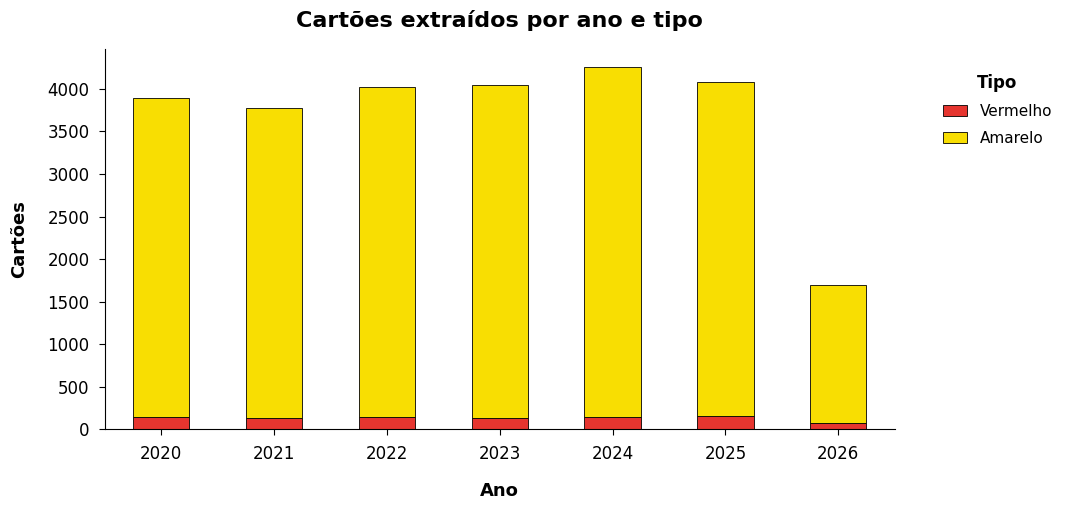

In [265]:
fig, ax = plt.subplots(figsize=(11, 5.4))
card_by_year_type.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[PLOT_CARD_COLORS.get(column, PLOT_BLUE) for column in card_by_year_type.columns],
    edgecolor="black",
    linewidth=0.6,
)
style_axis(ax, "Cartões extraídos por ano e tipo", "Ano", "Cartões")
handles, labels = ax.get_legend_handles_labels()
label_map = {"yellow": "Amarelo", "red": "Vermelho"}
ax.legend(handles, [label_map.get(label, label) for label in labels], title="Tipo", loc="upper left", bbox_to_anchor=(1.03, 1), frameon=False, borderaxespad=1.2, labelspacing=0.8, handlelength=1.6)
ax.get_legend().get_title().set_fontweight("bold")
plt.tight_layout(pad=1.5)
save_plot(fig, "cards_by_year_type.png")
plt.show()


In [266]:
card_text_counts = (
    cards.groupby(CARD_TEXT_KEY_COLUMN)
    .agg(
        text_for_embedding=(CARD_TEXT_COLUMN, "first"),
        n_events=(CARD_TEXT_COLUMN, "size"),
        n_yellow=("card_type", lambda values: (values == "yellow").sum()),
        n_red=("card_type", lambda values: (values == "red").sum()),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
    .reset_index(drop=True)
)

card_texts = card_text_counts["text_for_embedding"].tolist()
card_text_counts.head(25)


,card_reason_text_key,text_for_embedding,n_events,n_yellow,n_red
0,por calcar seu adversario de maneira temeraria na disputa de bola,Por calçar seu adversário de maneira temerária na disputa de bola.,500,500,0
1,por cometer uma falta tatica impedindo um ataque promissor,"Por cometer uma falta tática, impedindo um ataque promissor.",410,410,0
2,por retardar o reinicio de jogo,Por retardar o reinicio de jogo,333,333,0
3,cometer uma falta tatica para impedir um ataque promissor,Cometer uma falta tática para impedir um ataque promissor.,285,284,1
4,por cometer uma falta tatica para impedir um ataque promissor,Por cometer uma falta tática para impedir um ataque promissor.,248,247,1
5,por calcar seu adversario de maneira temeraria na disputa da bola,"Por calçar seu adversário de maneira temerária, na disputa da bola",237,237,0
6,por calcar seu adversario de forma temeraria na disputa de bola,Por calçar seu adversário de forma temerária na disputa de bola.,230,230,0
7,dar uma entrada contra um adversario de maneira temeraria na disputa da bola,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,224,223,1
8,por impedir um ataque promissor,Por impedir um ataque promissor.,203,203,0
9,por reclamar contra as decisoes da arbitragem,Por reclamar contra as decisões da arbitragem.,202,202,0


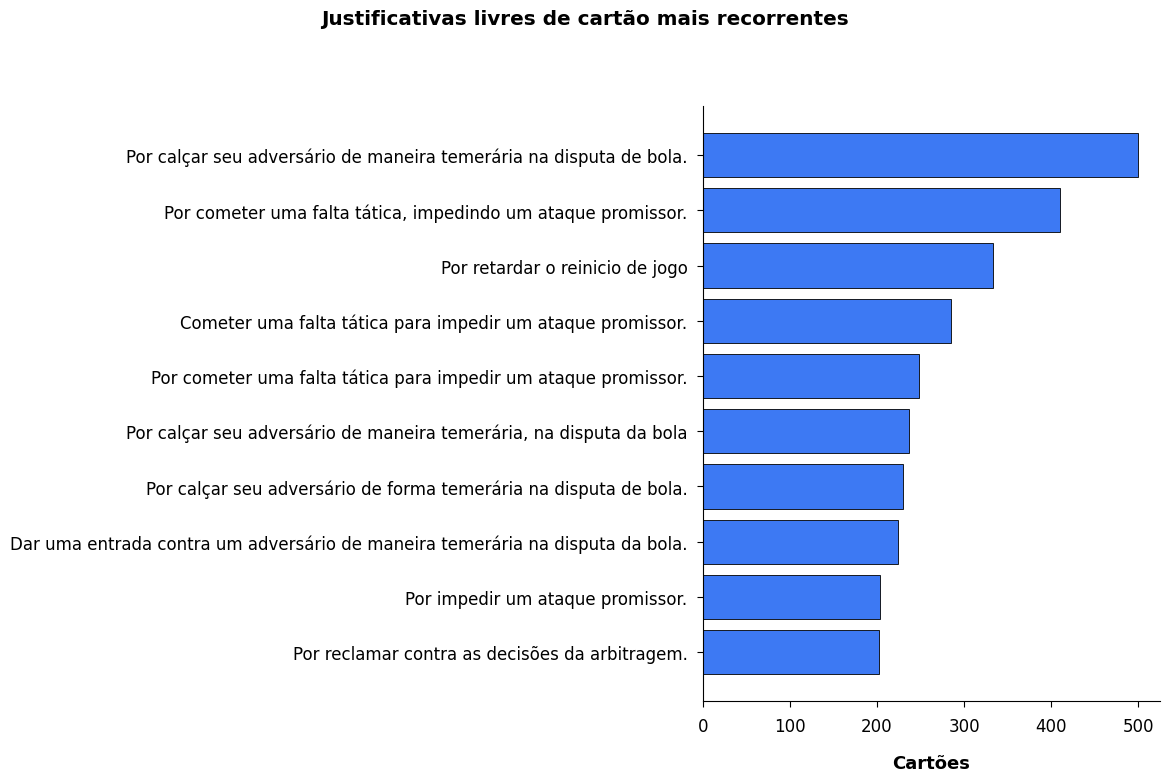

In [267]:
plot_top_texts = card_text_counts.head(TOP_N_CARD_TEXTS).sort_values("n_events")
fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(plot_top_texts["text_for_embedding"], plot_top_texts["n_events"], color=PLOT_BLUE, edgecolor="black", linewidth=0.6)
style_axis(ax, None, "Cartões", "")
fig.suptitle("Justificativas livres de cartão mais recorrentes", fontweight="bold", x=0.5, y=0.985)
plt.tight_layout(rect=(0, 0, 1, 0.95), pad=1.5)
save_plot(fig, "top_card_reason_texts.png")
plt.show()


## **5. Funções Auxiliares**

- `make_topic_model` — cria BERTopic com `embedding_model=None` para usar embeddings pré-calculados; UMAP com `n_components=5`, `metric="cosine"` e `min_dist=0.0` conforme recomendação do BERTopic.
- `load_embedding_model` — carrega `SentenceTransformer` com fallback para transformer puro + mean pooling.
- `silhouette_no_outliers` — exclui label -1 antes do Silhouette Score; incluir outliers como pseudo-classe inflaria artificialmente a métrica.
- `build_topic_summary` — agrega contagens de eventos e termos top por cluster.
- `top_examples_by_topic` — exemplos representativos por tópico, ordenados por frequência.
- `print_cluster_inspection` — formata clusters para inspeção antes da rotulagem semântica.


In [268]:
PORTUGUESE_STOPWORDS = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "na", "nas",
    "no", "nos", "o", "os", "ou", "para", "por", "que", "se", "sem", "um", "uma", "uns", "umas",
    "apos", "ate", "contra", "durante", "forma", "maneira", "motivo", "pela", "pelo", "pelas", "pelos",
    "num", "numa", "ter", "tendo", "dado", "haver", "havendo", "advertido", "advertida", "advertir",
    "adversario", "adversaria", "atleta", "jogador", "jogadora", "sr", "sra", "numero", "n", "equipe",
    "bola", "campo", "disputa", "jogada", "jogo", "partida", "seu", "sua", "seus", "suas", "foi", "foram",
    "acrescimo", "acrescimos", "devido", "inicio", "reinicio", "tempo", "minuto", "minutos", "jogadores",
}

def make_topic_model(min_topic_size: int, n_neighbors: int = 15) -> BERTopic:
    vectorizer_model = CountVectorizer(
        stop_words=list(PORTUGUESE_STOPWORDS),
        ngram_range=BERTOPIC_NGRAM_RANGE,
        min_df=2,
    )
    umap_model = umap.UMAP(n_components=5, n_neighbors=n_neighbors, min_dist=0.0, metric="cosine", random_state=RANDOM_STATE)
    return BERTopic(
        language="multilingual",
        embedding_model=None,
        umap_model=umap_model,
        vectorizer_model=vectorizer_model,
        min_topic_size=min_topic_size,
        calculate_probabilities=False,
        verbose=False,
    )

def silhouette_no_outliers(embeddings: np.ndarray, labels, sample_size: int = 3000) -> float:
    mask = np.array(labels) != -1
    if mask.sum() < 2:
        return float('nan')
    return float(
        silhouette_score(
            embeddings[mask], np.array(labels)[mask],
            sample_size=min(sample_size, int(mask.sum())),
            random_state=RANDOM_STATE,
        )
    )

def topic_words(topic_model: BERTopic, topic_id: int, top_n: int = 8) -> str:
    if topic_id == -1:
        return "outliers"
    words = topic_model.get_topic(topic_id) or []
    return ", ".join(word for word, _ in words[:top_n])

def build_topic_summary(topic_model: BERTopic, text_counts: pd.DataFrame, topic_col: str) -> pd.DataFrame:
    topic_info = topic_model.get_topic_info().rename(columns={"Topic": topic_col})
    event_counts = (
        text_counts.groupby(topic_col)
        .agg(
            n_unique_texts=("text_for_embedding", "size"),
            n_events=("n_events", "sum"),
        )
        .reset_index()
    )
    summary = topic_info.merge(event_counts, on=topic_col, how="left")
    summary["top_terms"] = summary[topic_col].map(lambda topic_id: topic_words(topic_model, int(topic_id)))
    return summary.sort_values("n_events", ascending=False).reset_index(drop=True)

def top_examples_by_topic(text_counts: pd.DataFrame, topic_col: str, top_n: int = 5) -> pd.DataFrame:
    columns = [topic_col, "n_events", "text_for_embedding"]
    return (
        text_counts.sort_values([topic_col, "n_events"], ascending=[True, False])
        .groupby(topic_col)
        .head(top_n)
        [columns]
        .reset_index(drop=True)
    )


def load_embedding_model(model_name_or_path) -> SentenceTransformer:
    path = str(model_name_or_path)
    try:
        model = SentenceTransformer(path)
        print(f"[OK] SentenceTransformer: {path}")
        return model
    except Exception:
        word_model = st_models.Transformer(path, max_seq_length=256)
        pooling = st_models.Pooling(
            word_model.get_word_embedding_dimension(),
            pooling_mode_mean_tokens=True,
        )
        model = SentenceTransformer(modules=[word_model, pooling])
        print(f"[OK] Transformer + mean pooling: {path}")
        return model

def model_dir_ready(path: Path) -> bool:
    return (path / "modules.json").exists()

def print_cluster_inspection(
    topic_model: BERTopic,
    text_counts: pd.DataFrame,
    topic_col: str,
    top_n_examples: int = 3,
) -> None:
    summary = build_topic_summary(topic_model, text_counts, topic_col)
    examples_df = top_examples_by_topic(text_counts, topic_col, top_n=top_n_examples)

    print(f"{'ID':>4}  {'Eventos':>8}  Top terms")
    print("-" * 110)
    for _, row in summary.iterrows():
        topic_id = int(row[topic_col])
        n_events = int(row.get("n_events", 0))
        terms = str(row["top_terms"])
        suffix = "  [outliers HDBSCAN]" if topic_id == -1 else ""
        print(f"\n{topic_id:>4}  {n_events:>8,}  {terms}{suffix}")
        examples = examples_df[examples_df[topic_col].eq(topic_id)]["text_for_embedding"].tolist()
        for example in examples:
            print(f"              > {str(example)[:108]}")


## **6. Pipeline NLP — Motivos de Cartão**

Arquitetura de duas passagens: o modelo base produz clusters exploratórios que geram os pares de treino para o fine-tuning; o modelo fine-tunado produz os clusters finais usados na rotulagem semântica.

### **6.1 Embeddings Base**

`multilingual-e5-large` (1024 dim) aplicado ao conjunto de textos únicos de justificativas. O modelo exige prefixos `passage:` nos textos a indexar e `query:` nas consultas — protocolo obrigatório da família E5 para maximizar a qualidade dos embeddings.

Trabalhar sobre textos únicos — e não sobre todas as ocorrências — reduz o custo computacional do UMAP+HDBSCAN e elimina o viés de duplicatas nos embeddings de cluster.


In [269]:
base_model = load_embedding_model(MODEL_NAME)

base_card_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
base_card_embeddings = np.asarray(base_card_embeddings)
print(f"Embeddings base: {base_card_embeddings.shape}")


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 4835.87it/s]


[OK] SentenceTransformer: intfloat/multilingual-e5-large


Batches: 100%|██████████| 109/109 [01:40<00:00,  1.09it/s]


Embeddings base: (6919, 1024)


### **6.2 Seleção de Hiperparâmetros UMAP e HDBSCAN**

Os dois parâmetros com maior impacto na qualidade dos clusters são `n_neighbors` (UMAP) e `min_topic_size` (HDBSCAN), conforme documentado por Grootendorst (2022):

- **`n_neighbors`** — equilíbrio entre estrutura local e global na projeção UMAP. Valores menores criam fronteiras mais nítidas; valores maiores capturam estrutura global.
- **`min_topic_size`** — threshold de densidade do HDBSCAN; determina o número de clusters e a taxa de outliers.

`min_dist=0.0` é fixado conforme recomendação explícita do BERTopic para maximizar a densidade dos clusters. O Silhouette Score (excluindo outliers HDBSCAN) é a métrica de seleção — maior score indica clusters mais coesos no espaço original de 768 dimensões. Os resultados do grid search são salvos em CSV e reutilizados em execuções subsequentes.


Grid search base carregado do cache (grid_search_results_base_intfloat_multilingual-e5-large.csv)

Melhores parâmetros (base): n_neighbors=30, min_topic_size=15
Silhouette: 0.1222 | clusters: 113 | outliers: 1312


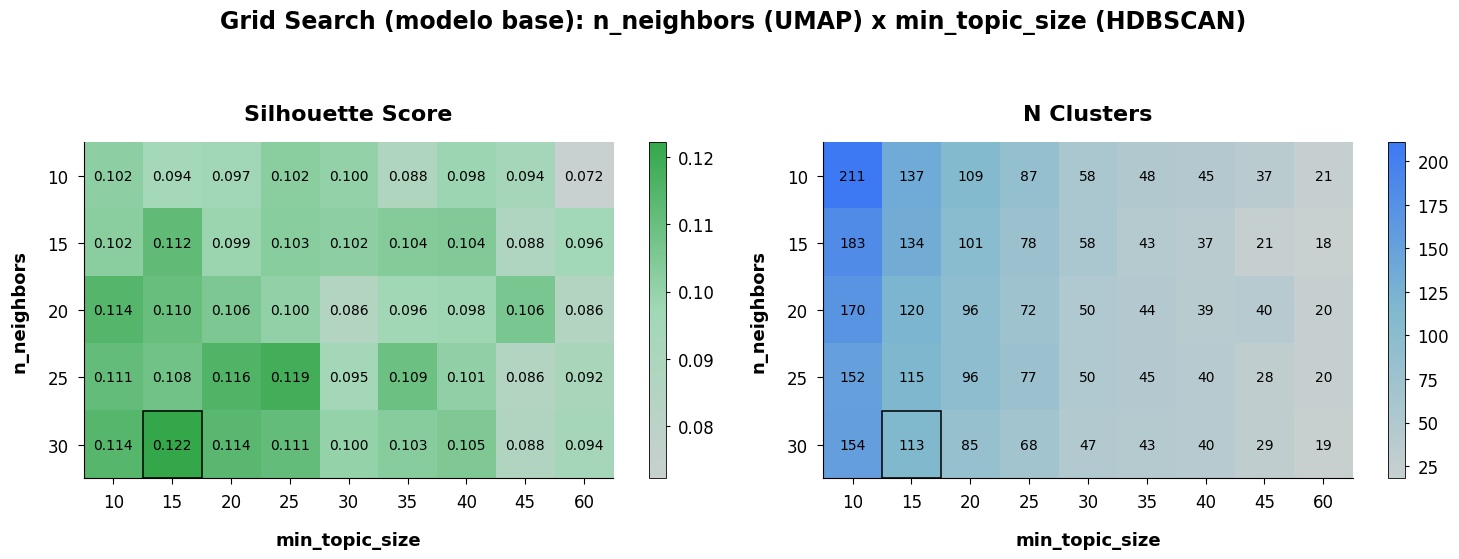

,n_neighbors,min_topic_size,n_clusters,n_outliers,outlier_pct,silhouette
0,10,10,211,1117,0.161,0.101547
1,10,15,137,1206,0.174,0.094154
2,10,20,109,1201,0.173,0.096995
3,10,25,87,1153,0.166,0.102480
4,10,30,58,733,0.106,0.100189
5,10,35,48,758,0.109,0.088195
6,10,40,45,1073,0.155,0.098248
7,10,45,37,695,0.100,0.093931
8,10,60,21,232,0.033,0.072225
9,15,10,183,1148,0.165,0.102346


In [270]:
MODEL_SLUG = MODEL_NAME.replace("/", "_")
GRID_SEARCH_BASE_PATH = OUTPUT_DIR / f"grid_search_results_base_{MODEL_SLUG}.csv"
RERUN_GRID_SEARCH = False

N_NEIGHBORS_RANGE = [10, 15, 20, 25, 30]
MIN_TOPIC_SIZE_RANGE = [10, 15, 20, 25, 30, 35, 40, 45, 60]

def _ranges_match(df: pd.DataFrame) -> bool:
    return (
        sorted(df["n_neighbors"].unique().tolist()) == sorted(N_NEIGHBORS_RANGE)
        and sorted(df["min_topic_size"].unique().tolist()) == sorted(MIN_TOPIC_SIZE_RANGE)
    )

def _run_grid_search(embeddings: np.ndarray, label: str) -> pd.DataFrame:
    combos = [(n, m) for n in N_NEIGHBORS_RANGE for m in MIN_TOPIC_SIZE_RANGE]
    results = []
    for i, (n_nb, mts) in enumerate(combos):
        _m = make_topic_model(mts, n_neighbors=n_nb)
        _topics, _ = _m.fit_transform(card_texts, embeddings=embeddings)
        _n_clusters = len(set(_topics) - {-1})
        _n_outliers = int((np.array(_topics) == -1).sum())
        _sil = silhouette_no_outliers(embeddings, _topics)
        results.append({"n_neighbors": n_nb, "min_topic_size": mts,
                         "n_clusters": _n_clusters, "n_outliers": _n_outliers,
                         "outlier_pct": round(_n_outliers / len(_topics), 3), "silhouette": _sil})
        print(f"  [{i+1:2d}/{len(combos)}] n_neighbors={n_nb:2d} | min_topic_size={mts:2d} | clusters={_n_clusters:3d} | outliers={_n_outliers:4d} | silhouette={float(_sil):.4f}")
    return pd.DataFrame(results)

if not RERUN_GRID_SEARCH and GRID_SEARCH_BASE_PATH.exists():
    grid_df = pd.read_csv(GRID_SEARCH_BASE_PATH)
    if not _ranges_match(grid_df):
        print("Ranges alterados — re-executando grid search base...")
        RERUN_GRID_SEARCH = True
    else:
        print(f"Grid search base carregado do cache ({GRID_SEARCH_BASE_PATH.name})")

if RERUN_GRID_SEARCH or not GRID_SEARCH_BASE_PATH.exists():
    print("Grid search: n_neighbors x min_topic_size (modelo base)...")
    grid_df = _run_grid_search(base_card_embeddings, "base")
    grid_df.to_csv(GRID_SEARCH_BASE_PATH, index=False)
    print(f"Salvo em {GRID_SEARCH_BASE_PATH}")

valid_grid = grid_df.dropna(subset=["silhouette"])
best_row = valid_grid.loc[valid_grid["silhouette"].idxmax()]
best_n_neighbors = int(best_row["n_neighbors"])
best_min_topic_size = int(best_row["min_topic_size"])
print()
print(f"Melhores parâmetros (base): n_neighbors={best_n_neighbors}, min_topic_size={best_min_topic_size}")
print(f"Silhouette: {best_row['silhouette']:.4f} | clusters: {int(best_row['n_clusters'])} | outliers: {int(best_row['n_outliers'])}")

sil_pivot = grid_df.pivot(index="n_neighbors", columns="min_topic_size", values="silhouette")
nc_pivot  = grid_df.pivot(index="n_neighbors", columns="min_topic_size", values="n_clusters")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, pivot, title, cmap in zip(
    axes, [sil_pivot, nc_pivot], ["Silhouette Score", "N Clusters"], [PLOT_HEATMAP_GREEN, PLOT_HEATMAP_BLUE],
):
    im = ax.imshow(pivot.values, aspect="auto", cmap=cmap)
    ax.set_xticks(range(len(MIN_TOPIC_SIZE_RANGE)))
    ax.set_xticklabels(MIN_TOPIC_SIZE_RANGE)
    ax.set_yticks(range(len(N_NEIGHBORS_RANGE)))
    ax.set_yticklabels(N_NEIGHBORS_RANGE)
    style_axis(ax, title, "min_topic_size", "n_neighbors")
    for ii in range(len(N_NEIGHBORS_RANGE)):
        for jj in range(len(MIN_TOPIC_SIZE_RANGE)):
            val = pivot.iloc[ii, jj]
            ax.text(jj, ii, f"{val:.3f}" if title == "Silhouette Score" else str(int(val)), ha="center", va="center", fontsize=10, color="black")
    colorbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.06)
    style_colorbar(colorbar)
    best_i = N_NEIGHBORS_RANGE.index(best_n_neighbors)
    best_j = MIN_TOPIC_SIZE_RANGE.index(best_min_topic_size)
    ax.add_patch(plt.Rectangle((best_j - 0.5, best_i - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=1.1))

fig.suptitle("Grid Search (modelo base): n_neighbors (UMAP) x min_topic_size (HDBSCAN)", fontsize=17, fontweight="bold", y=1.03)
plt.tight_layout(pad=1.6)
save_plot(fig, "umap_param_grid_search_base.png")
plt.show()
grid_df


### **6.3 BERTopic — Passagem 1 (Exploração)**

Clustering com o modelo base. Os tópicos encontrados **não** são os rótulos finais — servem exclusivamente como fonte de pares positivos para o fine-tuning. Textos no mesmo cluster HDBSCAN formam pares semanticamente coerentes; outliers (label -1) são descartados por não pertencerem a nenhum grupo denso.


In [271]:
card_topic_model_pass1 = make_topic_model(best_min_topic_size, n_neighbors=best_n_neighbors)
card_topics_pass1, _ = card_topic_model_pass1.fit_transform(card_texts, embeddings=base_card_embeddings)
card_text_counts["bertopic_topic_pass1"] = card_topics_pass1

n_clusters_pass1 = len(set(card_topics_pass1) - {-1})
n_outliers_pass1 = int((np.array(card_topics_pass1) == -1).sum())
sil_pass1 = silhouette_no_outliers(base_card_embeddings, card_topics_pass1)

pass1_counts = card_text_counts.rename(columns={"bertopic_topic_pass1": "bertopic_topic"})
pass1_summary = build_topic_summary(card_topic_model_pass1, pass1_counts, "bertopic_topic")
pass1_summary = pass1_summary.rename(columns={"bertopic_topic": "bertopic_topic_pass1"})

print(f"Pass 1 — clusters: {n_clusters_pass1} | outliers: {n_outliers_pass1} ({100*n_outliers_pass1/len(card_topics_pass1):.1f}%) | silhouette: {sil_pass1:.4f}")
pass1_summary.head(20)


Pass 1 — clusters: 112 | outliers: 1365 (19.7%) | silhouette: 0.1209


,bertopic_topic_pass1,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,-1,1365,-1_após_cartão_mesmo_arbitragem,"[após, cartão, mesmo, arbitragem, expulsei, expulso, decisões arbitragem, decisões, vermelho, cartão vermelho]","[Expulsei aos 32' (trinta e dois) minutos do 2º tempo, pelo cartão vermelho direto, o senhor: elton rodrigues brandão, nº 99 da equipe do sport club do recife, por trocar tapas e empurrões em seu adversário, o senhor...",1365,4177,outliers
1,11,99,11_calçar adversário temerária_temerária calçar_adversário temerária calçar_temerária calçar adversário,"[calçar adversário temerária, temerária calçar, adversário temerária calçar, temerária calçar adversário, calçar, calçar adversário, adversário temerária, calçar temerária adversário, calçar temerária, temerária]","[Por calçar seu adversário de maneira temerária em uma disputa de bola., Ao calçar o adversário de forma temerária., Por calçar o atleta adversário de forma temerária.]",99,2108,"calçar adversário temerária, temerária calçar, adversário temerária calçar, temerária calçar adversário, calçar, calçar adversário, adversário temerária, calçar temerária adversário"
2,1,126,1_dar entrada_entrada_temerária dar entrada_dar entrada adversário,"[dar entrada, entrada, temerária dar entrada, dar entrada adversário, entrada adversário, dar entrada temerária, adversário dar entrada, entrada temerária, entrada adversário temerária, dar]","[Dar uma entrada contra um adversário de forma temerária na disputa da bola., Dar uma entrada contra um adversário de maneira temerária na disputa de bola., Dar uma entrada em seu adversário de maneira temerária numa...",126,1406,"dar entrada, entrada, temerária dar entrada, dar entrada adversário, entrada adversário, dar entrada temerária, adversário dar entrada, entrada temerária"
3,25,70,25_entrada_entrada temerária_dar entrada_adversário dar entrada,"[entrada, entrada temerária, dar entrada, adversário dar entrada, dar entrada temerária, entrada temerária adversário, temerária adversário dar, adversário dar, dar, temerária adversário]","[Por dar uma entrada de maneira temerária em seu adversário na disputa d bola., Por dar uma entrada temerária em seu adversário na disputa da bola., Por dar uma entrada de forma temerária em sua adversário na disputa...",70,1224,"entrada, entrada temerária, dar entrada, adversário dar entrada, dar entrada temerária, entrada temerária adversário, temerária adversário dar, adversário dar"
4,9,99,9_temerária calçar_calçar_adversário temerária calçar_temerária calçar adversário,"[temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, adversário calçar, calçar temerária, adversário temerária, adversário calçar temerá...","[Calçar seu adversário na disputa da bola de maneira temerária., Calçar adversário em disputa de bola de maneira temerária., Calçar seu adversário de maneira temerária, na disputa da bola.]",99,1038,"temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, adversário calçar, calçar temerária"
5,33,64,33_ataque promissor cometer_promissor cometer_promissor cometer falta_tática,"[ataque promissor cometer, promissor cometer, promissor cometer falta, tática, falta tática, cometer falta, falta, cometer, ataque, ataque promissor]","[Por cometer uma falta tática para impedir uma ataque promissor., Advertido por cometer falta tática para impedir ataque promissor., Advertido por cometer uma falta tática para impedir ataque promissor.]",64,885,"ataque promissor cometer, promissor cometer, promissor cometer falta, tática, falta tática, cometer falta, falta, cometer"
6,21,75,21_arbitragem reclamar_arbitragem protestar_arbitragem_reclamar,"[arbitragem reclamar, arbitragem protestar, arbitragem, reclamar, protestar, decisões arbitragem reclamar, decisões, decisões arbitragem, decisões arbitragem protestar, decisão

### **6.4 Fine-Tuning do Sentence Transformer**

`MultipleNegativesRankingLoss` trata cada par `(âncora, positivo)` no batch como positivo; os demais positivos no mesmo batch atuam como negativos implícitos. Esta formulação — usada em dense retrieval (Karpukhin et al., 2020) e contrastive learning de sentenças (Gao et al., 2021 / SimCSE) — é eficiente computacionalmente e adequada para corpus pequeno com vocabulário especializado.

A geração automática de pares a partir dos clusters do BERTopic é uma forma de *self-supervised contrastive learning*: a própria estrutura semântica descoberta na Passagem 1 fornece o sinal de supervisão, sem necessidade de rótulos manuais.


In [272]:
def build_pairs_from_labels(
    text_counts: pd.DataFrame,
    labels,
    max_texts: int = MAX_TEXTS_PER_GROUP_FOR_FINETUNE,
    max_pairs: int = MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE,
    prefix: str = "",
) -> list[dict]:
    df = text_counts.copy()
    df["_label"] = labels
    pairs: list[dict] = []
    for lbl, group in df.groupby("_label"):
        if int(lbl) == -1:
            continue
        texts = (
            group.sort_values("n_events", ascending=False)["text_for_embedding"]
            .dropna().astype(str).str.strip()
            .loc[lambda s: s.ne("")]
            .drop_duplicates()
            .head(max_texts)
            .tolist()
        )
        pairs.extend(
            {"anchor": prefix + a, "positive": prefix + b}
            for a, b in list(combinations(texts, 2))[:max_pairs]
        )
    return pairs

if RUN_FINE_TUNING:
    if USE_FINETUNED_IF_AVAILABLE and model_dir_ready(FINETUNED_MODEL_DIR) and not RETRAIN_FINETUNED_MODEL:
        print(f"Modelo fine-tunado encontrado em {FINETUNED_MODEL_DIR}. Carregando.")
        embedding_model = load_embedding_model(FINETUNED_MODEL_DIR)
    else:
        import datasets as hf_datasets
        from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
        from sentence_transformers.losses import MultipleNegativesRankingLoss
        from sentence_transformers.training_args import BatchSamplers
        import sentence_transformers.base.trainer as st_base_trainer

        if not hasattr(st_base_trainer, "IterableDataset"):
            from torch.utils.data import IterableDataset as TorchIterableDataset
            st_base_trainer.IterableDataset = TorchIterableDataset

        if FINETUNED_MODEL_DIR.exists() and RETRAIN_FINETUNED_MODEL:
            shutil.rmtree(FINETUNED_MODEL_DIR)

        positive_pairs = build_pairs_from_labels(
            card_text_counts, card_topics_pass1, prefix=ENCODE_PREFIX_PASSAGE
        )
        n_outlier_texts = int((np.array(card_topics_pass1) == -1).sum())
        if not positive_pairs:
            raise ValueError("Nenhum par positivo gerado pelo BERTopic Pass 1.")
        print(f"Pares positivos gerados (BERTopic Pass 1): {len(positive_pairs):,}")
        print(f"Textos outlier excluídos: {n_outlier_texts}")

        train_dataset = hf_datasets.Dataset.from_list(positive_pairs)
        ft_model = load_embedding_model(MODEL_NAME)
        train_loss = MultipleNegativesRankingLoss(ft_model)
        training_args = SentenceTransformerTrainingArguments(
            output_dir=str(FINETUNED_MODEL_DIR / "checkpoints"),
            num_train_epochs=FINETUNE_EPOCHS,
            per_device_train_batch_size=FINETUNE_BATCH_SIZE,
            learning_rate=2e-5,
            warmup_ratio=0.1,
            fp16=False,
            use_cpu=True,
            batch_sampler=BatchSamplers.NO_DUPLICATES,
            save_strategy="no",
            logging_steps=50,
        )
        trainer = SentenceTransformerTrainer(
            model=ft_model,
            args=training_args,
            train_dataset=train_dataset,
            loss=train_loss,
        )
        trainer.train()
        ft_model.save(str(FINETUNED_MODEL_DIR))
        embedding_model = ft_model
        print(f"Modelo salvo em: {FINETUNED_MODEL_DIR}")
else:
    embedding_model = base_model
    print("Fine-tuning desabilitado. Usando modelo base.")

print(f"Dimensão dos embeddings: {embedding_model.get_sentence_embedding_dimension()}")


Modelo fine-tunado encontrado em /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_e5_large_two_pass. Carregando.


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 7082.80it/s]


[OK] SentenceTransformer: /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_e5_large_two_pass
Dimensão dos embeddings: 1024


### **6.5 BERTopic — Passagem 2 (Clusters Finais)**

O modelo fine-tunado gera embeddings com maior separabilidade intra-domínio. Um segundo grid search é executado sobre os embeddings fine-tunados — os hiperparâmetros ótimos podem diferir dos da Passagem 1, pois a geometria do espaço de embeddings muda após o fine-tuning.


In [273]:
card_embeddings = embedding_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
card_embeddings = np.asarray(card_embeddings)
print(f"Embeddings de cartões: {card_embeddings.shape}")


Batches:   0%|          | 0/109 [00:00<?, ?it/s]

Batches: 100%|██████████| 109/109 [00:59<00:00,  1.82it/s]

Embeddings de cartões: (6919, 1024)


In [274]:
GRID_SEARCH_FT_PATH = OUTPUT_DIR / f"grid_search_results_ft_{MODEL_SLUG}.csv"
RERUN_GRID_SEARCH_FT = RETRAIN_FINETUNED_MODEL

if not RERUN_GRID_SEARCH_FT and GRID_SEARCH_FT_PATH.exists():
    grid_ft_df = pd.read_csv(GRID_SEARCH_FT_PATH)
    if not _ranges_match(grid_ft_df):
        print("Ranges alterados — re-executando grid search FT...")
        RERUN_GRID_SEARCH_FT = True
    else:
        print(f"Grid search FT carregado do cache ({GRID_SEARCH_FT_PATH.name})")

if RERUN_GRID_SEARCH_FT or not GRID_SEARCH_FT_PATH.exists():
    print("Grid search: n_neighbors x min_topic_size (modelo fine-tunado)...")
    grid_ft_df = _run_grid_search(card_embeddings, "ft")
    grid_ft_df.to_csv(GRID_SEARCH_FT_PATH, index=False)
    print(f"Salvo em {GRID_SEARCH_FT_PATH}")

valid_ft = grid_ft_df.dropna(subset=["silhouette"])
best_row_ft = valid_ft.loc[valid_ft["silhouette"].idxmax()]
best_n_neighbors_ft = int(best_row_ft["n_neighbors"])
best_min_topic_size_ft = int(best_row_ft["min_topic_size"])
print(f"\nMelhores parâmetros (fine-tunado): n_neighbors={best_n_neighbors_ft}, min_topic_size={best_min_topic_size_ft}")
print(f"Silhouette: {best_row_ft['silhouette']:.4f} | clusters: {int(best_row_ft['n_clusters'])} | outliers: {int(best_row_ft['n_outliers'])}")


Grid search FT carregado do cache (grid_search_results_ft_intfloat_multilingual-e5-large.csv)

Melhores parâmetros (fine-tunado): n_neighbors=30, min_topic_size=25
Silhouette: 0.4658 | clusters: 101 | outliers: 380


In [275]:
card_topic_model = make_topic_model(best_min_topic_size_ft, n_neighbors=best_n_neighbors_ft)
card_topics, _ = card_topic_model.fit_transform(card_texts, embeddings=card_embeddings)
card_text_counts["bertopic_topic"] = card_topics

n_clusters_pass2 = len(set(card_topics) - {-1})
n_outliers_pass2 = int((np.array(card_topics) == -1).sum())
sil_pass2 = silhouette_no_outliers(card_embeddings, card_topics)

card_topic_summary = build_topic_summary(card_topic_model, card_text_counts, "bertopic_topic")
print(f"Pass 2 — clusters: {n_clusters_pass2} | outliers: {n_outliers_pass2} ({100*n_outliers_pass2/len(card_topics):.1f}%) | silhouette: {sil_pass2:.4f}")
card_topic_summary.head(20)


Pass 2 — clusters: 102 | outliers: 363 (5.2%) | silhouette: 0.4630


,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,8,106,8_calçar adversário temerária_calçar_calçar adversário_temerária calçar,"[calçar adversário temerária, calçar, calçar adversário, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário temerária, calçar temerária adversário, adversário ca...","[Ao calçar seu adversário de forma temerária na disputa de bola, Por calçar o atleta adversário de forma temerária., Por calçar adversário de forma temerária na disputa da bola.]",106,2147,"calçar adversário temerária, calçar, calçar adversário, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário temerária"
1,-1,363,-1_falta temerária_falta_cobrança falta_adverti,"[falta temerária, falta, cobrança falta, adverti, cobrança, tranco, cometer falta, cometer falta temerária, dar tranco, cometer]","[Por cometer uma falta temerária em seu adversário, na disputa da bola., Por cometer uma falta temerária contra o seu adversário., Cometer uma falta táctica impedindo um ataque promissor]",363,1554,outliers
2,12,100,12_entrada temerária_entrada_entrada temerária adversário_dar entrada temerária,"[entrada temerária, entrada, entrada temerária adversário, dar entrada temerária, dar entrada, adversário dar entrada, temerária adversário dar, temerária adversário, adversário dar, entrada adversário temerária]","[Por dar uma entrada de maneira temerária no adversário na disputa de bola., Por dar uma entrada temerária contra seu adversário na disputa de bola., Ao dar uma entrada temerária em seu adversário na disputa da bola.]",100,1330,"entrada temerária, entrada, entrada temerária adversário, dar entrada temerária, dar entrada, adversário dar entrada, temerária adversário dar, temerária adversário"
3,10,102,10_temerária calçar_calçar_adversário temerária calçar_temerária calçar adversário,"[temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, adversário calçar, calçar temerária, adversário temerária, calçar temerária calçar]","[Calçar seu adversário de forma temerária numa disputa., Calçar seu adversário de forma temerária na disputa da pela bola., Calçar seu adversário de forma temerária na disputa de bola.]",102,1052,"temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, adversário calçar, calçar temerária"
4,19,87,19_retardar_reinício_substituição_substituição retardar,"[retardar, reinício, substituição, substituição retardar, retardar reinício, reinício retardar, momento substituição, momento substituição retardar, reposição, retardar retardar]","[Por retardar o reinício de jogo durante uma substituição, Por retardar o reinício do jogo em uma substituição., Por retardar o reinício de jogo em uma substituição.]",87,892,"retardar, reinício, substituição, substituição retardar, retardar reinício, reinício retardar, momento substituição, momento substituição retardar"
5,43,65,43_promissor cometer_ataque promissor cometer_promissor cometer falta_tática,"[promissor cometer, ataque promissor cometer, promissor cometer falta, tática, cometer falta, falta tática, falta, cometer, ataque, ataque promissor]","[Advertido por cometer uma falta tática impedindo um ataque promissor., Advertido por cometer falta tática impedindo ataque promissor., Por cometer um falta tática para impedindo um ataque promissor.]",65,890,"promissor cometer, ataque promissor cometer, promissor cometer falta, tática, cometer falta, falta tática, falta, cometer"
6,15,98,15_dar entrada_entrada_entrada temerária_dar entrada temerária,"[dar entrada, entrada, entrada temerária, dar entrada temerária, temerária dar entrada, adversário dar entrada, dar entrada adversário, entrada adversário, dar, entrada temerária adversário]","[Dar uma entrada de maneira temerária contra seu adversári

In [276]:
card_topic_examples = top_examples_by_topic(card_text_counts, "bertopic_topic", top_n=5)
card_topic_examples.head(30)


,bertopic_topic,n_events,text_for_embedding
0,-1,285,Cometer uma falta tática para impedir um ataque promissor.
1,-1,203,Por impedir um ataque promissor.
2,-1,151,Cometer uma falta tática impedindo um ataque promissor.
3,-1,67,Reclamar contra as decisões da arbitragem
4,-1,55,Cometer uma falta tática impedindo ataque promissor.
5,0,2,"Por dar uma entrada no seu adversário, de maneira temerária, na disputa da bola. informo que após receber o cartão vermelho, o atleta saiu de campo normalmente."
6,0,2,"Por dar uma entrada nas pernas de seu adversario de forma temeraria, na disputa da bola. informo ainda que o atleta"
7,0,2,"Por ter golpeado com seu braço o rosto de seu adversário n° 7 sr. jonathan renato barbosa, do cuiabá, com uso de força excessiva na disputa de bola. o lance aconteceu no lado direito próximo a grande área no campo de..."
8,0,2,"Por ter segurado o seu adversário de nº 99 da equipe do botafogo, sr, igor jesus maciel da cruz, impedindo um ataque promissor. o fato aconteceu do lado esquerdo da aréa penal do campo de ataque da equipe do botafogo."
9,0,2,"Por dar uma entrada de forma temerária na disputa pela bola, contra seu adversário n.09 sr. matheus vieira campos peixoto."


### **6.6 Ablação: Modelo Base vs. Fine-Tunado**

Comparação direta entre Pass 1 (modelo base) e Pass 2 (modelo fine-tunado) usando os hiperparâmetros ótimos de cada passagem. As métricas — número de clusters, taxa de outliers e Silhouette Score — quantificam o ganho do fine-tuning na separabilidade semântica dos embeddings.

O modelo baseline (`paraphrase-multilingual-mpnet-base-v2`, 768 dim) foi avaliado na mesma configuração e serviu de referência para a adoção do `multilingual-e5-large`.


Ganho de silhouette: +283.0%


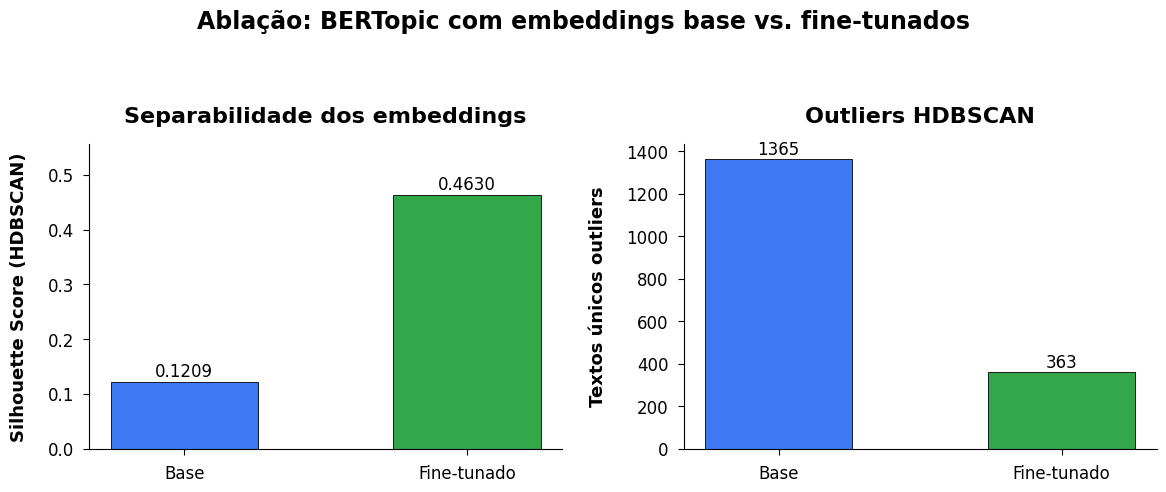

,Passagem,n_neighbors,min_topic_size,N Clusters,Outliers,Outlier %,Silhouette Score
0,Pass 1 — Modelo base,30,15,112,1365,19.7%,0.1209
1,Pass 2 — Fine-tunado,30,25,102,363,5.2%,0.4630


In [277]:
outlier_pct_pass1 = 100 * n_outliers_pass1 / len(card_topics_pass1)
outlier_pct_pass2 = 100 * n_outliers_pass2 / len(card_topics)
sil_gain = (sil_pass2 - sil_pass1) / sil_pass1 * 100

ablation_table = pd.DataFrame({
    "Passagem": ["Pass 1 — Modelo base", "Pass 2 — Fine-tunado"],
    "n_neighbors": [best_n_neighbors, best_n_neighbors_ft],
    "min_topic_size": [best_min_topic_size, best_min_topic_size_ft],
    "N Clusters": [n_clusters_pass1, n_clusters_pass2],
    "Outliers": [n_outliers_pass1, n_outliers_pass2],
    "Outlier %": [f"{outlier_pct_pass1:.1f}%", f"{outlier_pct_pass2:.1f}%"],
    "Silhouette Score": [round(sil_pass1, 4), round(sil_pass2, 4)],
})
print(f"Ganho de silhouette: +{sil_gain:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
labels = ["Base", "Fine-tunado"]
colors = [PLOT_BLUE, "#34A74B"]

axes[0].bar(labels, [sil_pass1, sil_pass2], color=colors, width=0.52, edgecolor="black", linewidth=0.6)
for ax_bar, val in zip(axes[0].patches, [sil_pass1, sil_pass2]):
    axes[0].text(ax_bar.get_x() + ax_bar.get_width() / 2, val + 0.003, f"{val:.4f}", ha="center", va="bottom", fontsize=12)
style_axis(axes[0], "Separabilidade dos embeddings", "", "Silhouette Score (HDBSCAN)")
axes[0].set_ylim(0, max(sil_pass1, sil_pass2) * 1.2)

axes[1].bar(labels, [n_outliers_pass1, n_outliers_pass2], color=colors, width=0.52, edgecolor="black", linewidth=0.6)
for ax_bar, val in zip(axes[1].patches, [n_outliers_pass1, n_outliers_pass2]):
    axes[1].text(ax_bar.get_x() + ax_bar.get_width() / 2, val + 0.5, str(val), ha="center", va="bottom", fontsize=12)
style_axis(axes[1], "Outliers HDBSCAN", "", "Textos únicos outliers")

fig.suptitle("Ablação: BERTopic com embeddings base vs. fine-tunados", fontsize=17, fontweight="bold", y=1.04)
plt.tight_layout(pad=1.6)
save_plot(fig, "ablation_silhouette.png")
plt.show()
ablation_table


## **7. Rotulagem Semântica Manual dos Clusters**

O BERTopic agrupa os textos, mas a decisão semântica final fica em arquivos manuais. A regra operacional é:

- clusters `0` a `101`: um grupo manual por cluster em `card_reason_manual_cluster_labels.csv`;
- outliers `-1`: um grupo manual por texto em `card_reason_manual_outlier_labels.csv`;
- âncoras lexicais de alta precisão são aplicadas antes do grupo do cluster para corrigir clusters mistos, especialmente `temerária/temerário`, `jogo brusco grave`, `força excessiva`, DOGSO, simulação, mão na bola e distância regulamentar.

A taxonomia segue a Regra 12 do IFAB e o Livro de Regras CBF 2025/2026, mas usa nomes adaptados ao vocabulário das súmulas. Como HDBSCAN marca ruído com `-1`, os outliers são tratados como itens auditáveis, não enviados a modelo generativo.

### Score de Representatividade

Para cada grupo, o notebook calcula um centroide ponderado por `n_events`. O score de cada texto é a similaridade cosseno entre o embedding do texto e o centroide do seu grupo. Também é calculada a margem contra o grupo alternativo mais próximo.

- `representativeness_score` alto: texto central no grupo proposto;
- `representativeness_margin` baixo: texto perto de outro grupo, bom candidato para revisão;
- `low_representativeness`: flag inicial para revisão manual.

### Referências

- [IFAB — Law 12: Fouls and Misconduct](https://www.theifab.com/laws/latest/fouls-and-misconduct/?hl=en-US)
- [CBF — Livro de Regras 2025/2026 Português/Brasileiro](https://www.cbf.com.br/a-cbf/por-dentro-da-cbf/informes/a/livro-de-regras-2025-2026)
- [BERTopic — embeddings + c-TF-IDF para tópicos interpretáveis](https://maartengr.github.io/BERTopic/api/bertopic.html)
- [BERTopic — outliers HDBSCAN rotulados como `-1`](https://maartengr.github.io/BERTopic/getting_started/outlier_reduction/outlier_reduction.html)
- [HDBSCAN — ruído e membership score](https://hdbscan.readthedocs.io/en/latest/basic_hdbscan.html)
- [multilingual-e5-large — prefixos `query:` e `passage:`](https://huggingface.co/intfloat/multilingual-e5-large)
- [Sentence Transformers — MultipleNegativesRankingLoss](https://www.sbert.net/docs/package_reference/sentence_transformer/losses.html?highlight=multiplenegativesrankingloss)
- [scikit-learn — cosine_similarity](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html)
- [scikit-learn — silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)


In [278]:
print_cluster_inspection(card_topic_model, card_text_counts, "bertopic_topic")


  ID   Eventos  Top terms
--------------------------------------------------------------------------------------------------------------

   8     2,147  calçar adversário temerária, calçar, calçar adversário, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário temerária
              > Por calçar seu adversário de maneira temerária na disputa de bola.
              > Por calçar seu adversário de maneira temerária, na disputa da bola
              > Por calçar seu adversário de forma temerária na disputa de bola.

  -1     1,554  outliers  [outliers HDBSCAN]
              > Cometer uma falta tática para impedir um ataque promissor.
              > Por impedir um ataque promissor.
              > Cometer uma falta tática impedindo um ataque promissor.

  12     1,330  entrada temerária, entrada, entrada temerária adversário, dar entrada temerária, dar entrada, adversário dar entrada, temerária adversário dar, temerária adversário
   

In [279]:
MANUAL_TAXONOMY_PATH = CARD_OUTPUT_DIR / "card_reason_group_taxonomy.csv"
MANUAL_CLUSTER_LABELS_PATH = CARD_OUTPUT_DIR / "card_reason_manual_cluster_labels.csv"
MANUAL_OUTLIER_LABELS_PATH = CARD_OUTPUT_DIR / "card_reason_manual_outlier_labels.csv"

GROUP_RENAMES = {"Impedir clara oportunidade de gol (DOGSO)": "Impedir clara oportunidade de gol"}
GROUP_CONTEXT_UPDATES = {
    "Jogo brusco grave": "Condutas físicas graves com jogo brusco grave, força excessiva, travas ou risco à integridade física na disputa de bola.",
    "Conduta violenta": "Violência ou agressão explícita fora da disputa normal de bola: soco, tapa, cabeçada, cusparada, peitada, golpe ou contato no pescoço.",
    "Impedir clara oportunidade de gol": "Infrações que impedem clara e manifesta oportunidade de gol por falta, carga, segurar ou mão quando descrito no texto.",
    "Agarrar ou segurar adversário": "Agarrar, segurar ou puxar adversário sem sinal explícito de ataque promissor, oportunidade clara de gol ou confronto físico mais amplo.",
    "Toque de mão na bola": "Toque ou bloqueio da bola com mão/braço, inclusive para interferir em ataque promissor, sem oportunidade clara de gol explícita.",
}

manual_taxonomy = pd.read_csv(MANUAL_TAXONOMY_PATH)
manual_cluster_labels = pd.read_csv(MANUAL_CLUSTER_LABELS_PATH)
manual_outlier_labels = pd.read_csv(MANUAL_OUTLIER_LABELS_PATH)

for frame in [manual_taxonomy, manual_cluster_labels, manual_outlier_labels]:
    frame["group"] = frame["group"].replace(GROUP_RENAMES)

manual_taxonomy = manual_taxonomy.drop_duplicates("group", keep="first").reset_index(drop=True)
if "Conduta violenta" not in set(manual_taxonomy["group"]):
    conduta_row = pd.DataFrame([{"group": "Conduta violenta", "context": GROUP_CONTEXT_UPDATES["Conduta violenta"]}])
    insert_at = manual_taxonomy.index[manual_taxonomy["group"].eq("Jogo brusco grave")]
    insert_at = int(insert_at[0] + 1) if len(insert_at) else len(manual_taxonomy)
    manual_taxonomy = pd.concat([manual_taxonomy.iloc[:insert_at], conduta_row, manual_taxonomy.iloc[insert_at:]], ignore_index=True)

for group, context in GROUP_CONTEXT_UPDATES.items():
    manual_taxonomy.loc[manual_taxonomy["group"].eq(group), "context"] = context

group_contexts = manual_taxonomy.set_index("group")["context"]
manual_cluster_labels["context"] = manual_cluster_labels["group"].map(group_contexts)
manual_outlier_labels["context"] = manual_outlier_labels["group"].map(group_contexts)

valid_groups = set(manual_taxonomy["group"])
cluster_topics = set(int(t) for t in card_text_counts["bertopic_topic"].unique() if int(t) != -1)
outlier_texts = set(card_text_counts.loc[card_text_counts["bertopic_topic"].eq(-1), "text_for_embedding"])
existing_outlier_texts = set(manual_outlier_labels["text"])

missing_clusters = cluster_topics - set(manual_cluster_labels["cluster"].astype(int))
missing_outlier_texts = sorted(outlier_texts - existing_outlier_texts)
invalid_cluster_groups = set(manual_cluster_labels["group"]) - valid_groups
invalid_outlier_groups = set(manual_outlier_labels["group"]) - valid_groups

if missing_clusters or invalid_cluster_groups or invalid_outlier_groups:
    raise ValueError({
        "missing_clusters": sorted(missing_clusters),
        "missing_outliers": len(missing_outlier_texts),
        "invalid_cluster_groups": sorted(invalid_cluster_groups),
        "invalid_outlier_groups": sorted(invalid_outlier_groups),
    })

pd.Series({
    "manual_groups": len(manual_taxonomy),
    "manual_clusters": len(manual_cluster_labels),
    "manual_outliers": len(manual_outlier_labels),
    "new_outliers_to_auto_label": len(missing_outlier_texts),
})


manual_groups                  18
manual_clusters               102
manual_outliers               484
new_outliers_to_auto_label      0
dtype: int64

In [280]:
CONDUTA_VIOLENTA_EXCLUSIONS = [
    r"socos? no ar",
    r"socos? no chao",
    r"tapa na bola",
    r"simul.*agress",
    r"temerari.{0,80}(na|em) disputa",
    r"(na|em) disputa.{0,80}temerari",
]

MANUAL_PATTERNS = {
    "Conduta violenta": [
        r"conduta violenta",
        r"\bpeitada\b",
        r"\bcabecad",
        r"\bcusp(?:iu|ir|indo|ida|arada)",
        r"\bbrutalidade\b",
        r"\bagred(?:ir|iu|indo|ido|e).*(adversario|arbitro|assistente|atleta|jogador|membro)",
        r"\bagressao\b.*(adversario|arbitro|assistente|atleta|jogador|membro)",
        r"apertar .*pescoco|segur.*pescoco|pescoco.*duas maos",
        r"desfer(?:ir|iu|indo)? .*(soco|tapa|cotovel|golpe|pontape)",
        r"\bsoco\b.*(adversario|rosto|orelha|pescoco|arbitro|assistente|preparador|atleta|jogador)",
        r"\btapa\b.*(rosto|adversario|antebraco|peito|nuca|costas|braco|orelha)",
        r"fora da disputa.*(soco|tapa|cotovel|golp|desfer|ating|chut|pontape|braco|mao|pis)",
        r"(soco|tapa|cotovel|golp|pontape|chute).*(fora da disputa|jogo paralisado|bola fora|fora de jogo)",
        r"(jogo paralisado|bola fora|fora de jogo).*(soco|tapa|cotovel|golp|desfer|ating|cabecad|pescoco|pis)",
    ],
    "Jogo brusco grave": [r"\bjogo brusco grave\b", r"forca excessiva", r"\btravas\b.*(integridade|canela|tornozelo|barriga)"],
    "Impedir clara oportunidade de gol": [r"oportunidade clara", r"clara .*oportunidade", r"manifesta oportunidade", r"\bdogso\b"],
    "Ação temerária": [r"temerari", r"temeridad", r"falta temeraria"],
    "Simulação": [r"\bsimul", r"enganar .*arbitro"],
    "Comemoração irregular": [r"comemor", r"tirar .*camisa", r"retirar .*camisa", r"subir .*arquibancada", r"subir .*alambrado", r"provocativ.*torcida"],
    "Não respeitar distância regulamentar": [r"distancia regulamentar", r"distancia da barreira", r"distancia correta", r"distancia regulamentada"],
    "Retardar reinício do jogo": [r"retardar", r"demorar excessivamente", r"impedir .*cobranca", r"retardar .*saida", r"segur.*bola.*reinicio", r"bola.*maos.*reinicio"],
    "Toque de mão na bola": [r"mao na bola", r"tocar .*bola .*mao", r"colocar .*mao .*bola", r"bloquear .*bola .*braco", r"bola .*mao"],
    "Entrar ou sair do campo sem autorização": [r"entrar .*campo.*sem", r"retornar .*campo.*sem", r"reentrar", r"sem autorizacao", r"sem permissao", r"marcas nao autorizadas"],
    "Gesto ou linguagem ofensiva": [r"filho da puta", r"vai tomar", r"tomar no cu", r"caralho", r"porra", r"merda", r"safado", r"ladrao", r"incompetente", r"maluca", r"gesto obsceno", r"dedo medio", r"orgao genital", r"palavras ofensivas", r"injurios"],
    "Falta tática em ataque promissor": [r"ataque promissor", r"impedir .*ataque", r"impedindo .*ataque", r"cortando .*ataque", r"motivo tatico", r"posicao vantajosa", r"falta tatica"],
    "Insubordinação da comissão técnica": [r"banco de reservas", r"banco de suplentes", r"area tecnica", r"suplente", r"substituto", r"tecnico", r"treinador", r"auxiliar", r"preparador", r"medico", r"massagista", r"comissao tecnica"],
    "Protesto contra a arbitragem": [r"reclam", r"protest", r"desapro", r"contesta", r"question", r"discord", r"aplaud.*iron", r"decisao .*arbitr", r"decisoes .*arbitr", r"marcacao .*arbitr", r"marcacoes .*arbitr"],
    "Agarrar ou segurar adversário": [r"agarr", r"segur", r"pux", r"camisa", r"camiseta"],
    "Confronto físico com adversário": [r"empurr", r"trocar empurroes", r"confront", r"discut", r"desentend", r"tumulto", r"peitada"],
    "Infringir persistentemente as regras": [r"infringir persistentemente", r"numero de diferentes infracoes"],
    "Conduta antidesportiva": [r"conduta antidesportiva", r"atitude antidesportiva", r"desrespeito ao jogo", r"falta de respeito"],
}


def lexical_group(text: str) -> str | None:
    normalized = normalize_text(text)
    for group, patterns in MANUAL_PATTERNS.items():
        if group == "Conduta violenta" and any(re.search(pattern, normalized) for pattern in CONDUTA_VIOLENTA_EXCLUSIONS):
            continue
        if any(re.search(pattern, normalized) for pattern in patterns):
            return group
    return None


In [281]:
cluster_to_group = manual_cluster_labels.set_index("cluster")["group"].to_dict()
group_contexts = manual_taxonomy.set_index("group")["context"]

missing_outlier_rows = []
next_outlier_rank = int(manual_outlier_labels["outlier_rank"].max() + 1) if "outlier_rank" in manual_outlier_labels and len(manual_outlier_labels) else 0
outlier_event_counts = card_text_counts.loc[card_text_counts["bertopic_topic"].eq(-1)].set_index("text_for_embedding")["n_events"].to_dict()

for offset, text in enumerate(missing_outlier_texts):
    group = lexical_group(text) or "Conduta antidesportiva"
    missing_outlier_rows.append({
        "outlier_rank": next_outlier_rank + offset,
        "text": text,
        "group": group,
        "context": group_contexts.loc[group],
        "n_events": int(outlier_event_counts.get(text, 0)),
        "manual_basis": "auto: lexical rule" if lexical_group(text) else "auto: missing outlier fallback",
    })

if missing_outlier_rows:
    manual_outlier_labels = pd.concat([manual_outlier_labels, pd.DataFrame(missing_outlier_rows)], ignore_index=True)

outlier_to_group = manual_outlier_labels.set_index("text")["group"].to_dict()


def assign_card_reason_group(row: pd.Series) -> str:
    topic = int(row["bertopic_topic"])
    lexical = lexical_group(row["text_for_embedding"])
    if lexical == "Conduta violenta":
        return lexical
    if topic == -1:
        return outlier_to_group.get(row["text_for_embedding"], lexical or "Conduta antidesportiva")
    return lexical if lexical is not None else cluster_to_group[topic]

card_text_counts["manual_cluster_group"] = card_text_counts["bertopic_topic"].map(cluster_to_group)
card_text_counts.loc[card_text_counts["bertopic_topic"].eq(-1), "manual_cluster_group"] = "OUTLIER_MANUAL"
card_text_counts["manual_lexical_group"] = card_text_counts["text_for_embedding"].map(lexical_group)
card_text_counts.loc[
    card_text_counts["bertopic_topic"].eq(-1) & card_text_counts["manual_lexical_group"].ne("Conduta violenta"),
    "manual_lexical_group",
] = np.nan
card_text_counts["card_reason_group"] = card_text_counts.apply(assign_card_reason_group, axis=1)
card_text_counts["card_reason_group_context"] = card_text_counts["card_reason_group"].map(group_contexts)

group_map = card_text_counts.set_index(CARD_TEXT_KEY_COLUMN)["card_reason_group"]
group_context_map = card_text_counts.set_index(CARD_TEXT_KEY_COLUMN)["card_reason_group_context"]
cards["card_reason_group"] = cards[CARD_TEXT_KEY_COLUMN].map(group_map).fillna("Conduta antidesportiva")
cards["card_reason_group_context"] = cards[CARD_TEXT_KEY_COLUMN].map(group_context_map).fillna(group_contexts.loc["Conduta antidesportiva"])
CARD_GROUPS = sorted(cards["card_reason_group"].unique())
CARD_GROUP_COLOR_MAP = {group: PLOT_PALETTE[i % len(PLOT_PALETTE)] for i, group in enumerate(CARD_GROUPS)}

pd.Series({
    "manual_groups": len(CARD_GROUPS),
    "manual_clusters": len(cluster_to_group),
    "manual_outliers": len(outlier_to_group),
    "auto_outliers_added": len(missing_outlier_rows),
    "lexical_overrides": int(card_text_counts["manual_lexical_group"].notna().sum()),
    "unlabeled_cards": int(cards["card_reason_group"].isna().sum()),
})


manual_groups            18
manual_clusters         102
manual_outliers         484
auto_outliers_added       0
lexical_overrides      6074
unlabeled_cards           0
dtype: int64

In [282]:
group_order = sorted(card_text_counts["card_reason_group"].unique())
group_to_idx = {group: i for i, group in enumerate(group_order)}
centroids = []

for group in group_order:
    mask = card_text_counts["card_reason_group"].eq(group).to_numpy()
    weights = card_text_counts.loc[mask, "n_events"].to_numpy(dtype=float)
    centroid = np.average(card_embeddings[mask], axis=0, weights=weights)
    centroid = centroid / np.linalg.norm(centroid)
    centroids.append(centroid)

centroid_matrix = np.vstack(centroids)
similarity_to_groups = card_embeddings @ centroid_matrix.T
own_idx = card_text_counts["card_reason_group"].map(group_to_idx).to_numpy()
row_idx = np.arange(len(card_text_counts))
other_similarity = similarity_to_groups.copy()
other_similarity[row_idx, own_idx] = -np.inf
nearest_other_idx = other_similarity.argmax(axis=1)

card_text_counts["representativeness_score"] = similarity_to_groups[row_idx, own_idx]
card_text_counts["nearest_other_group"] = [group_order[i] for i in nearest_other_idx]
card_text_counts["nearest_other_score"] = other_similarity[row_idx, nearest_other_idx]
card_text_counts["representativeness_margin"] = card_text_counts["representativeness_score"] - card_text_counts["nearest_other_score"]
card_text_counts["low_representativeness"] = (
    card_text_counts["representativeness_score"].lt(REPRESENTATIVENESS_MIN_SCORE)
    | card_text_counts["representativeness_margin"].lt(REPRESENTATIVENESS_MIN_MARGIN)
)

card_group_quality = (
    card_text_counts.groupby("card_reason_group")
    .agg(
        n_unique_texts=("text_for_embedding", "size"),
        n_events=("n_events", "sum"),
        score_mean=("representativeness_score", "mean"),
        score_p10=("representativeness_score", lambda s: s.quantile(0.10)),
        margin_mean=("representativeness_margin", "mean"),
        low_score_texts=("low_representativeness", "sum"),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
)

cluster_quality = (
    card_text_counts[card_text_counts["bertopic_topic"].ne(-1)]
    .groupby("bertopic_topic")
    .agg(
        n_unique_texts=("text_for_embedding", "size"),
        n_events=("n_events", "sum"),
        score_mean=("representativeness_score", "mean"),
        score_p10=("representativeness_score", lambda s: s.quantile(0.10)),
        margin_mean=("representativeness_margin", "mean"),
        low_score_texts=("low_representativeness", "sum"),
    )
    .reset_index()
)

cluster_dominant_group = (
    card_text_counts[card_text_counts["bertopic_topic"].ne(-1)]
    .groupby(["bertopic_topic", "card_reason_group"], as_index=False)["n_events"].sum()
    .sort_values(["bertopic_topic", "n_events"], ascending=[True, False])
    .drop_duplicates("bertopic_topic")
    .rename(columns={"card_reason_group": "dominant_group", "n_events": "dominant_group_events"})
)

card_reason_label_audit_clusters = (
    cluster_quality
    .merge(cluster_dominant_group, on="bertopic_topic", how="left")
    .merge(card_topic_summary[["bertopic_topic", "top_terms"]], on="bertopic_topic", how="left")
    .sort_values(["low_score_texts", "score_p10"], ascending=[False, True])
)

card_reason_label_audit_terms = card_text_counts.sort_values(
    ["low_representativeness", "representativeness_margin", "representativeness_score"],
    ascending=[False, True, True],
)[[
    CARD_TEXT_KEY_COLUMN, "text_for_embedding", "n_events", "bertopic_topic", "card_reason_group",
    "manual_cluster_group", "manual_lexical_group", "representativeness_score", "nearest_other_group",
    "nearest_other_score", "representativeness_margin", "low_representativeness",
]]

card_reason_label_audit_outliers = card_reason_label_audit_terms[card_reason_label_audit_terms["bertopic_topic"].eq(-1)]
card_group_quality


,card_reason_group,n_unique_texts,n_events,score_mean,score_p10,margin_mean,low_score_texts
1,Ação temerária,1941,11270,0.445897,0.215069,0.002210,1783
14,Protesto contra a arbitragem,935,3902,0.635816,0.480109,0.140302,583
7,Falta tática em ataque promissor,782,3701,0.609609,0.319770,0.070676,529
15,Retardar reinício do jogo,533,1662,0.590163,0.398993,0.159089,444
0,Agarrar ou segurar adversário,581,1195,0.606819,0.433345,0.123738,443
5,Confronto físico com adversário,440,931,0.642072,0.413768,0.053229,254
3,Conduta antidesportiva,220,643,0.564832,0.237193,-0.005040,173
11,Insubordinação da comissão técnica,335,504,0.650604,0.453400,0.013918,198
2,Comemoração irregular,261,435,0.744506,0.563610,0.274796,87
10,Infringir persistentemente as regras,54,278,0.828884,0.571303,0.162195,14


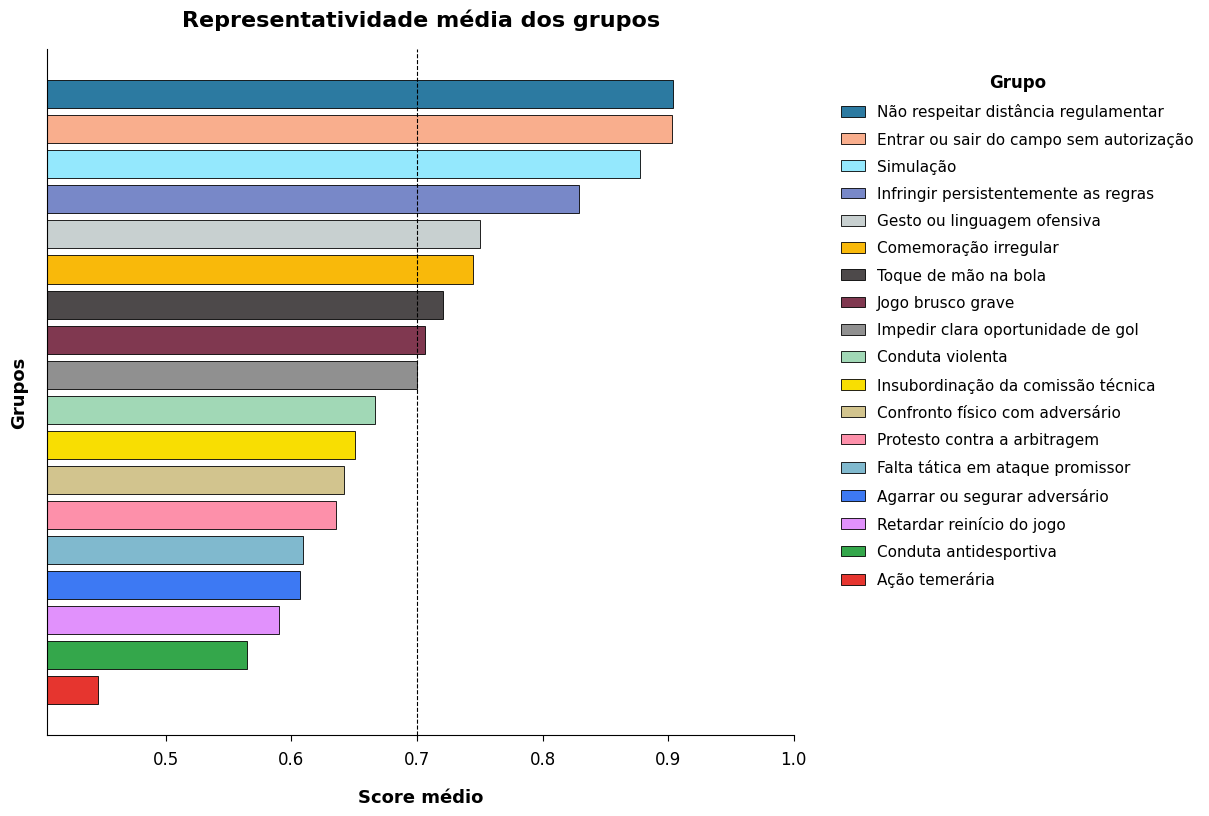

,card_reason_group,n_events,n_unique_texts,score_mean,score_p10,margin_mean,low_score_texts
1,Ação temerária,11270,1941,0.445897,0.215069,0.002210,1783
3,Conduta antidesportiva,643,220,0.564832,0.237193,-0.005040,173
15,Retardar reinício do jogo,1662,533,0.590163,0.398993,0.159089,444
0,Agarrar ou segurar adversário,1195,581,0.606819,0.433345,0.123738,443
7,Falta tática em ataque promissor,3701,782,0.609609,0.319770,0.070676,529
14,Protesto contra a arbitragem,3902,935,0.635816,0.480109,0.140302,583
5,Confronto físico com adversário,931,440,0.642072,0.413768,0.053229,254
11,Insubordinação da comissão técnica,504,335,0.650604,0.453400,0.013918,198
4,Conduta violenta,175,131,0.666339,0.395840,-0.080427,124
9,Impedir clara oportunidade de gol,138,101,0.700166,0.411840,0.059384,49


In [283]:
representativeness_plot = card_group_quality.sort_values("score_mean", ascending=True).copy()
groups_by_score = representativeness_plot["card_reason_group"].tolist()
legend_groups_by_score = groups_by_score[::-1]
fig, ax = plt.subplots(figsize=(12.5, 8.5))
ax.barh(
    range(len(representativeness_plot)),
    representativeness_plot["score_mean"],
    color=plot_colors(groups_by_score),
    edgecolor="black",
    linewidth=0.6,
)
ax.set_yticks([])
ax.tick_params(axis="y", length=0)
ax.axvline(REPRESENTATIVENESS_MIN_SCORE, color="black", linewidth=0.8, linestyle="--")
x_min = max(0, min(representativeness_plot["score_mean"].min(), REPRESENTATIVENESS_MIN_SCORE) - 0.04)
ax.set_xlim(x_min, 1)
style_axis(ax, "Representatividade média dos grupos", "Score médio", "Grupos")
ax.legend(handles=group_legend_handles(legend_groups_by_score), title="Grupo", loc="upper left", bbox_to_anchor=(1.03, 1), frameon=False, borderaxespad=1.2, labelspacing=0.8, handlelength=1.6)
ax.get_legend().get_title().set_fontweight("bold")
plt.tight_layout(pad=1.6)
save_plot(fig, "card_reason_representativeness.png")
plt.show()

representativeness_plot[["card_reason_group", "n_events", "n_unique_texts", "score_mean", "score_p10", "margin_mean", "low_score_texts"]]


## **8. Resultados — Motivos de Cartão**

Cada cartão recebe `card_reason_group` a partir da taxonomia manual. A tabela `card_group_quality` resume se os textos de cada grupo são semanticamente próximos do centroide do grupo; as auditorias detalhadas ficam nos arquivos `card_reason_label_audit_*`.

### **8.1 Distribuição Geral**


In [284]:
card_group_summary = (
    cards.groupby("card_reason_group")
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
)
card_group_summary["pct_events"] = (card_group_summary["n_events"] / len(cards)).round(4)
card_group_summary


,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,pct_events
1,Ação temerária,11270,11183,87,1941,0.4376
14,Protesto contra a arbitragem,3902,3870,32,935,0.1515
7,Falta tática em ataque promissor,3701,3670,31,782,0.1437
15,Retardar reinício do jogo,1662,1646,16,533,0.0645
0,Agarrar ou segurar adversário,1195,1176,19,581,0.0464
5,Confronto físico com adversário,931,903,28,440,0.0362
3,Conduta antidesportiva,643,640,3,220,0.0250
11,Insubordinação da comissão técnica,504,381,123,335,0.0196
2,Comemoração irregular,435,426,9,261,0.0169
10,Infringir persistentemente as regras,278,278,0,54,0.0108


In [285]:
card_group_by_year = pd.crosstab(cards["year"], cards["card_reason_group"], normalize="index").round(3)
card_group_by_year


card_reason_group,Agarrar ou segurar adversário,Ação temerária,Comemoração irregular,Conduta antidesportiva,Conduta violenta,Confronto físico com adversário,Entrar ou sair do campo sem autorização,Falta tática em ataque promissor,Gesto ou linguagem ofensiva,Impedir clara oportunidade de gol,Infringir persistentemente as regras,Insubordinação da comissão técnica,Jogo brusco grave,Não respeitar distância regulamentar,Protesto contra a arbitragem,Retardar reinício do jogo,Simulação,Toque de mão na bola
year,,,,,,,,,,,,,,,,,,
2020,0.024,0.481,0.013,0.017,0.008,0.027,0.003,0.154,0.008,0.006,0.014,0.015,0.010,0.002,0.141,0.059,0.006,0.013
2021,0.034,0.498,0.015,0.022,0.007,0.030,0.002,0.125,0.006,0.005,0.011,0.019,0.008,0.002,0.153,0.050,0.002,0.012
2022,0.047,0.443,0.021,0.031,0.009,0.040,0.002,0.116,0.005,0.006,0.014,0.020,0.007,0.001,0.163,0.061,0.002,0.010
2023,0.054,0.431,0.017,0.027,0.004,0.034,0.002,0.136,0.005,0.007,0.011,0.020,0.009,0.001,0.154,0.068,0.007,0.013
2024,0.054,0.399,0.016,0.026,0.005,0.041,0.004,0.150,0.007,0.005,0.008,0.023,0.009,0.000,0.157,0.078,0.007,0.009
2025,0.054,0.400,0.018,0.022,0.007,0.044,0.004,0.173,0.004,0.003,0.008,0.022,0.012,0.001,0.146,0.067,0.007,0.007
2026,0.070,0.393,0.019,0.037,0.010,0.035,0.004,0.161,0.008,0.006,0.007,0.015,0.009,0.001,0.138,0.066,0.013,0.008


In [286]:
card_group_by_type = pd.crosstab(cards["card_type"], cards["card_reason_group"])
card_group_by_type


card_reason_group,Agarrar ou segurar adversário,Ação temerária,Comemoração irregular,Conduta antidesportiva,Conduta violenta,Confronto físico com adversário,Entrar ou sair do campo sem autorização,Falta tática em ataque promissor,Gesto ou linguagem ofensiva,Impedir clara oportunidade de gol,Infringir persistentemente as regras,Insubordinação da comissão técnica,Jogo brusco grave,Não respeitar distância regulamentar,Protesto contra a arbitragem,Retardar reinício do jogo,Simulação,Toque de mão na bola
card_type,,,,,,,,,,,,,,,,,,
red,19,87,9,3,143,28,8,31,126,93,0,123,211,0,32,16,1,4
yellow,1176,11183,426,640,32,903,66,3670,29,45,278,381,26,32,3870,1646,148,267


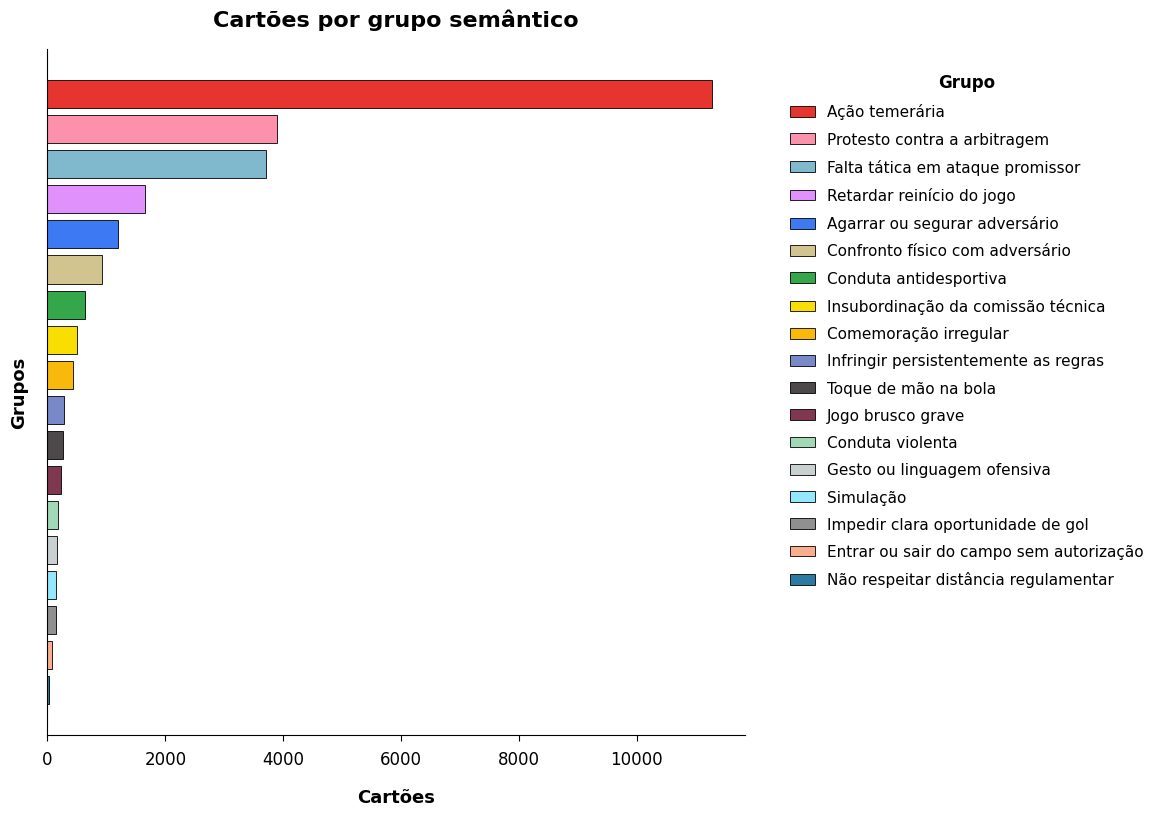

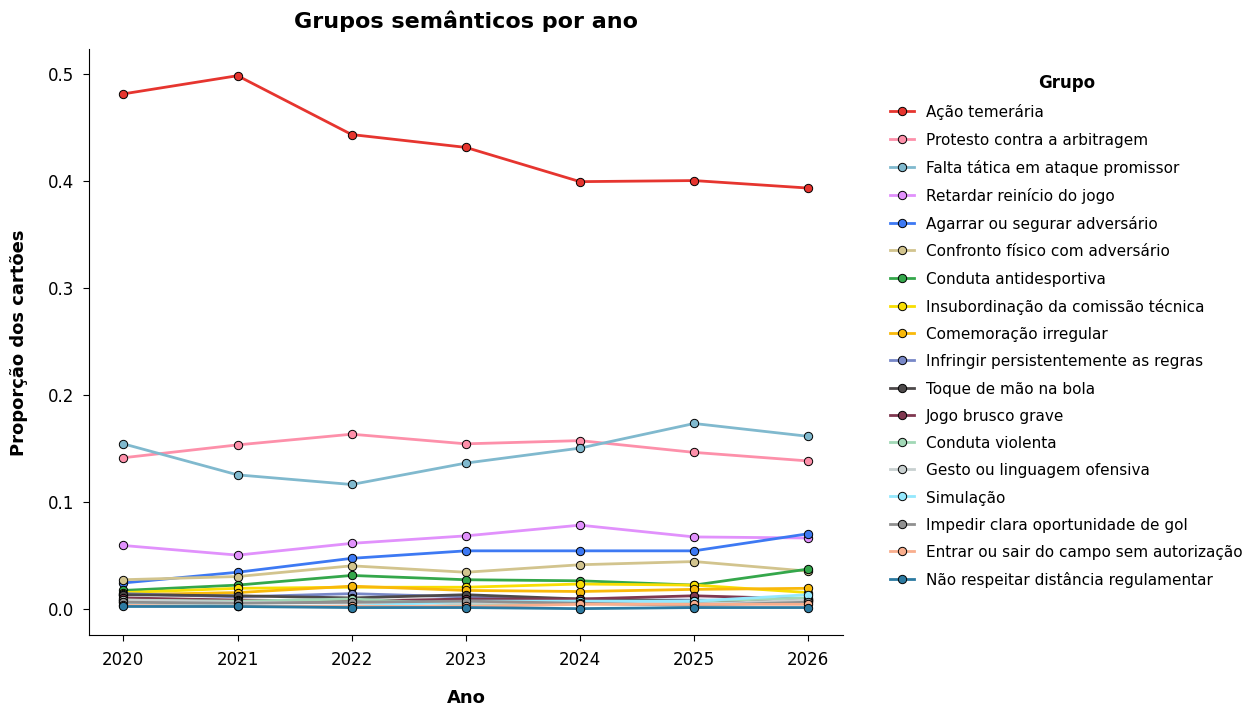

In [287]:
plot_card_summary = card_group_summary.sort_values("n_events", ascending=True)
groups_by_count = plot_card_summary["card_reason_group"].tolist()
legend_groups_by_count = groups_by_count[::-1]

fig, ax = plt.subplots(figsize=(12, 8.5))
ax.barh(
    range(len(plot_card_summary)),
    plot_card_summary["n_events"],
    color=plot_colors(groups_by_count),
    edgecolor="black",
    linewidth=0.6,
)
ax.set_yticks([])
ax.tick_params(axis="y", length=0)
style_axis(ax, "Cartões por grupo semântico", "Cartões", "Grupos")
ax.legend(handles=group_legend_handles(legend_groups_by_count), title="Grupo", loc="upper left", bbox_to_anchor=(1.03, 1), frameon=False, borderaxespad=1.2, labelspacing=0.8, handlelength=1.6)
ax.get_legend().get_title().set_fontweight("bold")
plt.tight_layout(pad=1.6)
save_plot(fig, "card_reason_groups_counts.png")
plt.show()

all_groups = card_group_summary["card_reason_group"].tolist()
fig, ax = plt.subplots(figsize=(13, 7.5))
card_group_by_year[all_groups].plot(ax=ax, marker="o", color=plot_colors(all_groups))
style_axis(ax, "Grupos semânticos por ano", "Ano", "Proporção dos cartões")
style_lines(ax)
style_legend(ax, "Grupo", bbox_to_anchor=(1.03, 1))
plt.tight_layout(pad=1.6)
save_plot(fig, "card_reason_groups_proportions_by_year.png")
plt.show()


### **8.2 Por Time**

Para cada time, a tabela detalha a contagem de cada grupo semântico nos cartões recebidos. O perfil de motivos reflete o estilo de jogo: times com proporção elevada de "Ataque promissor / falta tática" tendem a ter linha defensiva mais agressiva; times com mais "Protesto contra arbitragem" apresentam comportamento mais reativo.


In [288]:
card_reason_by_team = (
    cards.groupby(["team", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
team_card_totals = cards.groupby("team").size().rename("total_cards")
card_reason_by_team = card_reason_by_team.merge(team_card_totals, on="team", how="left")
card_reason_by_team["pct_team_cards"] = (card_reason_by_team["n_events"] / card_reason_by_team["total_cards"]).round(4)
card_reason_by_team = card_reason_by_team.sort_values(["total_cards", "team", "n_events"], ascending=[False, True, False])

card_reason_top_by_team = (
    card_reason_by_team.sort_values(["team", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("team")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_team.head(TOP_N_TEAMS)


,team,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_team_cards
0,Red Bull Bragantino,Ação temerária,478,473,5,160,999,0.4785
1,Fluminense,Ação temerária,432,432,0,157,991,0.4359
2,Internacional,Ação temerária,400,399,1,138,953,0.4197
3,São Paulo,Ação temerária,380,375,5,139,950,0.4000
4,Palmeiras,Ação temerária,385,380,5,126,937,0.4109
5,Corinthians,Ação temerária,439,436,3,155,936,0.4690
6,Athletico Paranaense,Ação temerária,373,373,0,132,883,0.4224
7,Atlético Mineiro,Ação temerária,362,360,2,125,877,0.4128
8,Fortaleza Esporte Clube,Ação temerária,367,362,5,129,851,0.4313
9,Flamengo,Ação temerária,411,409,2,154,834,0.4928


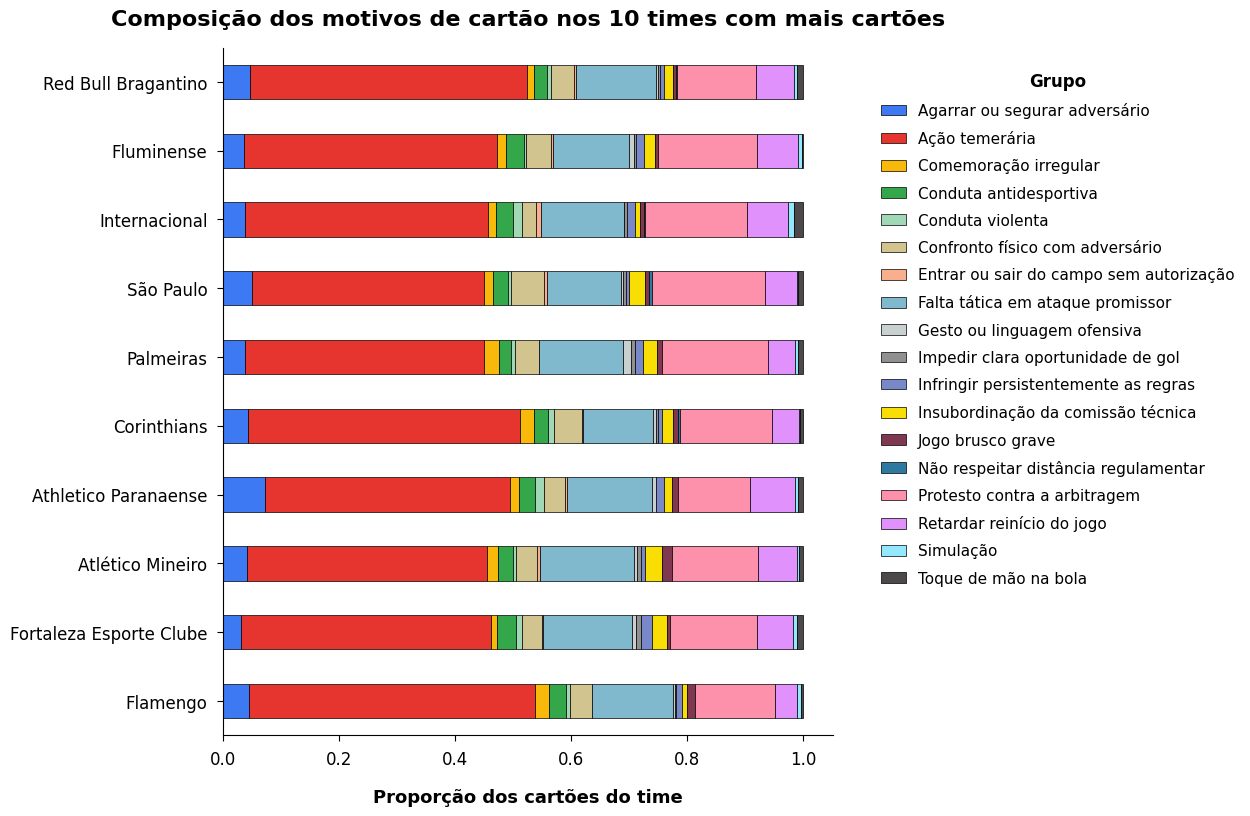

In [289]:
top_card_teams = cards["team"].value_counts().head(TOP_N_TEAMS).index
team_group_plot = pd.crosstab(
    cards.loc[cards["team"].isin(top_card_teams), "team"],
    cards.loc[cards["team"].isin(top_card_teams), "card_reason_group"],
    normalize="index",
).loc[top_card_teams]
team_group_plot = team_group_plot.reindex(columns=CARD_GROUPS, fill_value=0)

fig, ax = plt.subplots(figsize=(13, 8.5))
team_group_plot.plot(kind="barh", stacked=True, ax=ax, color=plot_colors(team_group_plot.columns), edgecolor="black", linewidth=0.5)
ax.invert_yaxis()
style_axis(ax, f"Composição dos motivos de cartão nos {TOP_N_TEAMS} times com mais cartões", "Proporção dos cartões do time", "")
style_legend(ax, "Grupo")
plt.tight_layout(pad=1.6)
save_plot(fig, "card_reason_groups_by_team.png")
plt.show()


### **8.3 Por Árbitro**

A distribuição por árbitro mostra quais tipos de infrações são mais marcados nas partidas de cada árbitro. Árbitros com proporção elevada de "Protesto contra arbitragem" tendem a ser mais rigorosos com reclamações; árbitros com mais "Falta temerária" marcam faltas mais físicas.


In [290]:
card_reason_by_referee = (
    cards.groupby(["arbitro", "arbitro_short", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
referee_card_totals = cards.groupby(["arbitro", "arbitro_short"]).size().rename("total_cards").reset_index()
card_reason_by_referee = card_reason_by_referee.merge(referee_card_totals, on=["arbitro", "arbitro_short"], how="left")
card_reason_by_referee["pct_referee_cards"] = (card_reason_by_referee["n_events"] / card_reason_by_referee["total_cards"]).round(4)
card_reason_by_referee = card_reason_by_referee.sort_values(["total_cards", "arbitro", "n_events"], ascending=[False, True, False])

card_reason_top_by_referee = (
    card_reason_by_referee.sort_values(["arbitro", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("arbitro")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_referee.head(TOP_N_REFEREES)


,arbitro,arbitro_short,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_referee_cards
0,Braulio da Silva Machado,Braulio da Silva,Ação temerária,531,531,0,107,1178,0.4508
1,Wilton Pereira Sampaio,Wilton Pereira,Ação temerária,500,492,8,151,1078,0.4638
2,Bruno Arleu de Araujo,Bruno Arleu,Ação temerária,541,541,0,165,1037,0.5217
3,Ramon Abatti Abel,Ramon Abatti,Ação temerária,434,429,5,167,993,0.4371
4,Flavio Rodrigues de Souza,Flavio Rodrigues,Ação temerária,397,392,5,129,921,0.4311
5,Raphael Claus,Raphael Claus,Ação temerária,449,447,2,137,911,0.4929
6,Anderson Daronco,Anderson Daronco,Ação temerária,416,414,2,136,909,0.4576
7,Felipe Fernandes de Lima,Felipe Fernandes,Ação temerária,329,329,0,135,847,0.3884
8,Savio Pereira Sampaio,Savio Pereira,Ação temerária,343,338,5,130,829,0.4138
9,Wagner do Nascimento Magalhaes,Wagner do Nascimento,Ação temerária,388,386,2,135,799,0.4856


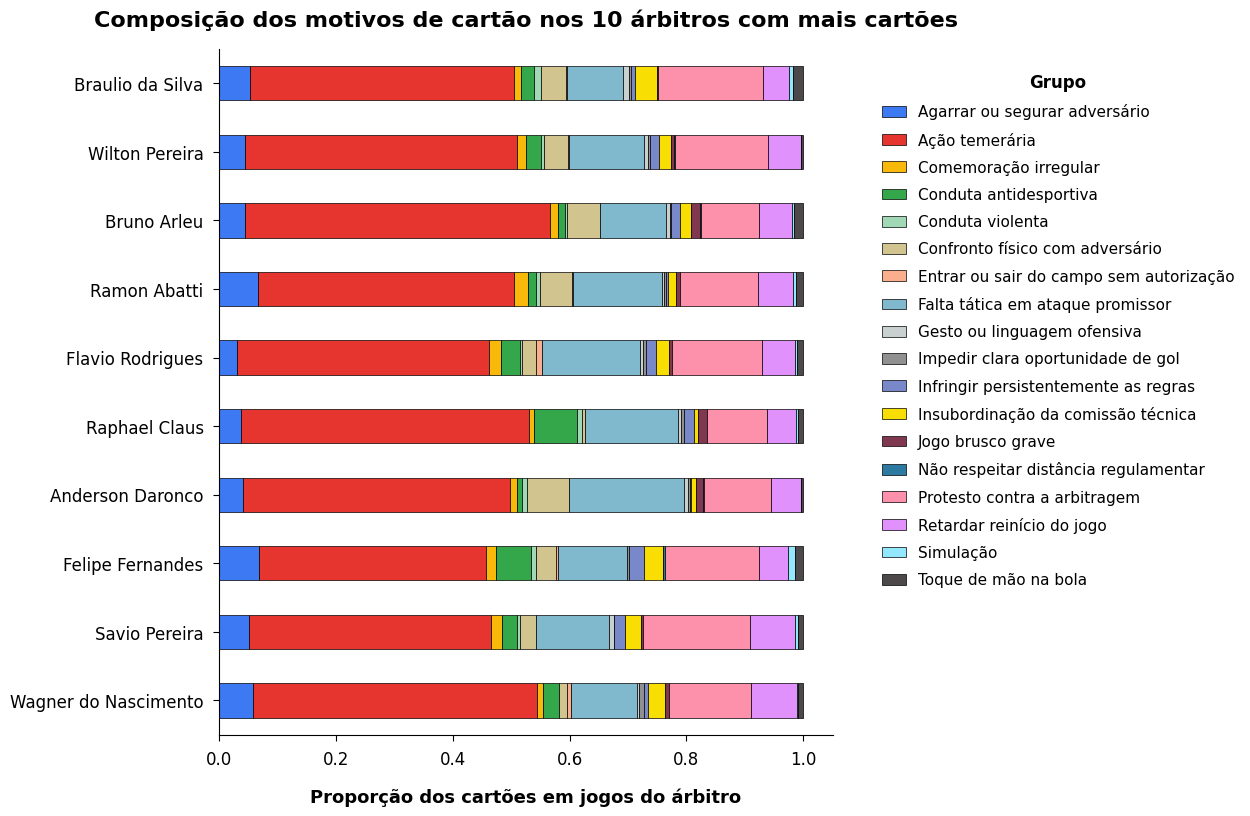

In [291]:
top_card_referees = cards["arbitro"].value_counts().head(TOP_N_REFEREES).index
referee_plot_cards = cards[cards["arbitro"].isin(top_card_referees)].copy()
referee_group_plot = pd.crosstab(
    referee_plot_cards["arbitro"],
    referee_plot_cards["card_reason_group"],
    normalize="index",
).loc[top_card_referees]
referee_group_plot = referee_group_plot.reindex(columns=CARD_GROUPS, fill_value=0)
referee_labels = cards.drop_duplicates("arbitro").set_index("arbitro").loc[top_card_referees, "arbitro_short"]
referee_group_plot.index = referee_labels

fig, ax = plt.subplots(figsize=(13, 8.5))
referee_group_plot.plot(kind="barh", stacked=True, ax=ax, color=plot_colors(referee_group_plot.columns), edgecolor="black", linewidth=0.5)
ax.invert_yaxis()
style_axis(ax, f"Composição dos motivos de cartão nos {TOP_N_REFEREES} árbitros com mais cartões", "Proporção dos cartões em jogos do árbitro", "")
style_legend(ax, "Grupo")
plt.tight_layout(pad=1.6)
save_plot(fig, "card_reason_groups_by_referee.png")
plt.show()


### **8.4 Busca Semântica (Diagnóstico)**

Recupera os textos mais similares a uma consulta livre no espaço de embeddings fine-tunados. Útil para auditar se expressões semanticamente equivalentes ficaram no mesmo grupo e verificar a cobertura dos protótipos.


In [292]:
def embed_query(text: str) -> np.ndarray:
    return np.asarray(embedding_model.encode([ENCODE_PREFIX_QUERY + text], normalize_embeddings=True))

def semantic_search_cards(query: str, top_k: int = 10) -> pd.DataFrame:
    query_embedding = embed_query(query)
    similarities = cosine_similarity(query_embedding, card_embeddings).ravel()
    result = card_text_counts.copy()
    result["similarity"] = similarities
    return result.sort_values("similarity", ascending=False)[[
        "similarity", "n_events", "card_reason_group", "representativeness_score",
        "representativeness_margin", "nearest_other_group", "bertopic_topic", "text_for_embedding",
    ]].head(top_k)

semantic_search_cards("reclamação contra arbitragem", top_k=10)


,similarity,n_events,card_reason_group,representativeness_score,representativeness_margin,nearest_other_group,bertopic_topic,text_for_embedding
5042,0.917318,1,Protesto contra a arbitragem,0.807718,0.394447,Insubordinação da comissão técnica,-1,Reclamar com arbitragem.
881,0.909394,4,Protesto contra a arbitragem,0.800168,0.430280,Insubordinação da comissão técnica,-1,Reclamação contra a arbitragem.
107,0.901274,30,Protesto contra a arbitragem,0.809890,0.438468,Insubordinação da comissão técnica,-1,Reclamar das decisões da arbitragem
1088,0.900900,3,Protesto contra a arbitragem,0.819399,0.388983,Insubordinação da comissão técnica,-1,Reclamar das marcações da arbitragem
1411,0.898229,2,Protesto contra a arbitragem,0.825812,0.409247,Insubordinação da comissão técnica,-1,Reclamação com a arbitragem com palavras
5027,0.897968,1,Protesto contra a arbitragem,0.793189,0.449989,Insubordinação da comissão técnica,-1,Reclamação contra a decisão da arbitragem
4480,0.894857,1,Protesto contra a arbitragem,0.802342,0.439159,Insubordinação da comissão técnica,-1,Reclamar contra decisões da arbitragem
48,0.893855,67,Protesto contra a arbitragem,0.806694,0.438591,Insubordinação da comissão técnica,-1,Reclamar contra as decisões da arbitragem
422,0.888547,7,Protesto contra a arbitragem,0.798822,0.403071,Insubordinação da comissão técnica,36,Por reclamação contra a arbitragem.
6349,0.886919,1,Protesto contra a arbitragem,0.804723,0.369834,Insubordinação da comissão técnica,36,Por reclamacao contra arbitragem.


## **9. Motivos de Acréscimos e Detecção de VAR**

Os motivos de acréscimos são tratados separadamente dos cartões. O único objetivo analítico é detectar se há menção ao VAR na justificativa de acréscimo registrada pelo árbitro.

A detecção é **léxica** — expressões regulares sobre o texto normalizado. Esta abordagem é suficiente porque a presença de VAR é um sinal fortemente textual: árbitros mencionam explicitamente "VAR", "AVAR", "revisão de vídeo" etc. quando o protocolo é ativado.

### **9.1 Exploração dos Textos de Atraso (BERTopic)**

BERTopic aplicado ao corpus de textos de atraso para mapear a diversidade temática. Esta etapa é exploratória — os clusters não são usados na detecção de VAR.


In [293]:
delay_text_counts = (
    delays[delays[DELAY_TEXT_COLUMN].ne("n/a")]
    .groupby("delay_reason_key")
    .agg(
        text_for_embedding=(DELAY_TEXT_COLUMN, "first"),
        n_games=(DELAY_TEXT_COLUMN, "size"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .reset_index()
    .sort_values("n_games", ascending=False)
    .reset_index(drop=True)
)
delay_text_counts.head(25)


,delay_reason_key,text_for_embedding,n_games,first_year,last_year
0,acrescimos devido as substituicoes e atendimento medico aos atletas,Acréscimos devido as substituições e atendimento médico aos atletas.,30,2020,2026
1,acrescimos devido substituicoes e transporte de atletas lesionados,Acréscimos devido substituições e transporte de atletas lesionados.,22,2020,2021
2,acrescimos devido a substituicoes atendimento medico e retirada de atletas supostamente lesionados do campo de jogo,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo.",14,2021,2023
3,acrescimos devido a substituicoes e atendimento de atletas supostamente lesionados,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .,13,2020,2025
4,acrescimos devido substituicoes atendimento medico aos atletas lesionados e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas.",13,2021,2025
5,acrescimos devido as substituicoes atendimento medico aos atletas e checagem do var,"Acréscimos devido as substituições, atendimento médico aos atletas e checagem do var.",12,2020,2022
6,nao houve atraso no inicio e reinicio de jogo acrescimos motivados por substituicoes e atendimento a jogadores supostamente lesionados,-nao houve atraso no inicio e reinicio de jogo.-acrescimos motivados por substituições e atendimento a jogadores supostamente lesionados.,11,2021,2025
7,acrescimos devido substituicoes atendimento medico aos atletas lesionados checagens do var e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados, checagens do var e paralisações diversas.",11,2023,2024
8,acrescimos devido substituicoes atendimento medico aos atletas lesionados e checagens do var,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e checagens do var.",11,2020,2022
9,acrescimos devido paralisacoes substituicoes e atendimento de atletas supostamente lesionados,"Acréscimos devido paralisações, substituições e atendimento de atletas supostamente lesionados.",10,2020,2024


In [294]:
delay_texts = delay_text_counts["text_for_embedding"].tolist()
delay_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in delay_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
delay_embeddings = np.asarray(delay_embeddings)
print(f"Embeddings de atrasos/acréscimos: {delay_embeddings.shape}")


Batches: 100%|██████████| 59/59 [01:26<00:00,  1.46s/it]

Embeddings de atrasos/acréscimos: (3764, 1024)


In [295]:
delay_topic_model = make_topic_model(DELAY_MIN_TOPIC_SIZE)
delay_topics, _ = delay_topic_model.fit_transform(delay_texts, embeddings=delay_embeddings)
delay_text_counts["bertopic_topic"] = delay_topics

delay_text_counts_for_summary = delay_text_counts.rename(columns={"n_games": "n_events"})
delay_topic_summary = build_topic_summary(delay_topic_model, delay_text_counts_for_summary, "bertopic_topic")
delay_topic_summary.head(20)


,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,0,879,0_substituições_acréscimos_atendimento_atletas,"[substituições, acréscimos, atendimento, atletas, lesionados, supostamente, supostamente lesionados, acréscimos substituições, substituições atendimento, atletas supostamente]","[Acréscimos para substituições e atendimento a atletas supostamente lesionados., Acréscimos devido as substituições e atendimento de atletas supostamente lesionados., Acréscimos devido à substituições e atendimento à...",879,1458,"substituições, acréscimos, atendimento, atletas, lesionados, supostamente, supostamente lesionados, acréscimos substituições"
1,1,426,1_homenagem_silêncio_respeitado_silêncio homenagem,"[homenagem, silêncio, respeitado, silêncio homenagem, homenagem póstuma, póstuma, respeitado silêncio, acréscimos, substituições, covid]","[Acréscimos devido a substituições, retirada de atletas supostamente lesionados do campo de jogo, reposição de bola e checagem do var. foi respeitado um minuto de silêncio em homenagem póstuma as vítimas do covid-19....",426,621,"homenagem, silêncio, respeitado, silêncio homenagem, homenagem póstuma, póstuma, respeitado silêncio, acréscimos"
2,-1,422,-1_atraso_ilustre_torcedor_fluminense,"[atraso, ilustre, torcedor, fluminense, entrada, informo, substituições, flamengo, acréscimos, lesionados]","[Informo que a equipe do sport clube do recife, retornou do intervalo de jogo com atraso de dois minutos, por este motivo o segundo tempo de jogo iniciou com atraso de um minuto. acréscimos motivados por atendimento ...",422,598,outliers
3,2,370,2_não_não houve_houve_não houve atraso,"[não, não houve, houve, não houve atraso, houve atraso, acréscimos, substituições, atrasos, atrasos acréscimos, houve atraso acréscimos]","[Não houve atraso. acréscimos por substituições e retirada de atletas supostamente lesionados., Não houve atraso. acréscimos devido a substituições, atendimento de atletas supostamente lesionados e reposição de bola....",370,542,"não, não houve, houve, não houve atraso, houve atraso, acréscimos, substituições, atrasos"
4,3,282,3_não houve_não_houve_homenagem,"[não houve, não, houve, homenagem, não houve atraso, silêncio, houve atraso, póstuma, homenagem póstuma, respeitado]","[Não houve atrasos. acréscimos devido as substituições, retirada de atletas supostamente lesionados e reposição de bola.informo que antes da partida foi respeitado um minuto de silêncio em homenagem póstuma as vitima...",282,451,"não houve, não, houve, homenagem, não houve atraso, silêncio, houve atraso, póstuma"
5,4,255,4_homenagem_silêncio_covid_respeitado,"[homenagem, silêncio, covid, respeitado, 19, covid 19, silêncio homenagem, acréscimos, 19 acréscimos, substituições]","[Foi respeitado 1 minuto de silêncio em homenagem as vitimas da covid 19.acréscimos devido a substituições e atendimento de atletas supostamente lesionados., Foi respeitado 1 minuto de silêncio de homenagem as vítima...",255,341,"homenagem, silêncio, covid, respeitado, 19, covid 19, silêncio homenagem, acréscimos"
6,6,188,6_primeiro_segundo_primeiro segundo_acréscimos primeiro,"[primeiro, segundo, primeiro segundo, acréscimos primeiro, segundo paralisações substituições, segundo paralisações, substituições, lesionados, atendimento, paralisações substituições]","[Acréscimos de 6 minutos no primeiro tempo, e 6 minutos no segundo tempo devido a paralisações, substituições, atendimento a atletas lesionados e checagem do var., Acréscimos de 6 minutos no primeiro tempo, e 7 minut...",188,277,"primeiro, segundo, primeiro segundo, acréscimos primeiro, segundo paralisações substituições, segundo paralisações, substituições, lesionados"
7,5,202,5_atraso_entrada_reinício_acréscimos,"[atraso, entrada, reinício, acréscimos, equipes, substituições, ambas, segundo, ambas equipes, atletas]",[Informo que ambas as equipes atrasaram em 5 minutos sua entrada em campo para a execução do protocolo de entrada e hino. em virtude d

In [296]:
delay_topic_examples = top_examples_by_topic(
    delay_text_counts.rename(columns={"n_games": "n_events"}),
    "bertopic_topic",
    top_n=5,
).rename(columns={"n_events": "n_games"})
delay_topic_examples.head(30)


,bertopic_topic,n_games,text_for_embedding
0,-1,2,"- acrescimos devido substituições , retirada de atletas do campo e revisões na ara.- concedido um minuto de silencio em homenagem postuma ao sr denis leitao de castro."
1,-1,2,"Acréscimos em função de atendimento a atletas supostamente lesionados, entrada da maca, substituições, checagem do var e comemorações de gols. informo que a equipe do bahia retornou para reinicio do jogo (segundo tem..."
2,-1,2,* acrescimos devido substituições e retirada de atletas do campo de jogo.* concedido um minuto de silencio em homenagem postuma as vitimas da covid19.
3,-1,2,Acrescimos devido substituições e retirada de atletas do campo de jogo. foi concedido um minuto de silencio em homenagem postumas a diego armando maradona e as vitimas da covid 19.
4,-1,2,Acréscimos devidos as substituições e atendimentos médico aos atletas lesionados.informo que a partida inicio com 2 minutos de atraso devido ao atraso de são paulo futebol clube de 3 minutos e da equipe saf botafogo ...
5,0,30,Acréscimos devido as substituições e atendimento médico aos atletas.
6,0,22,Acréscimos devido substituições e transporte de atletas lesionados.
7,0,14,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo."
8,0,13,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .
9,0,13,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas."


### **9.2 Detecção Léxica de VAR**

Os padrões cobrem siglas institucionais (`VAR`, `AVAR`, `VOR`, `ARA`), variações descritivas (`árbitro de vídeo`), termos de processo (`checagem`, `revisão`, `review`) e referências a infraestrutura (`monitor`, `cabine`). O sinal `monitor_cabine` é o mais ambíguo — "monitor" pode aparecer em contextos não-VAR.


In [297]:
VAR_SIGNAL_PATTERNS = {
    "var": r"\bvar\b",
    "avar": r"\bavar\b",
    "vor": r"\bvor\b|sala\s+vor",
    "ara": r"\bara\b",
    "arbitro_de_video": r"arbitro\s+de\s+video|arbitragem\s+de\s+video|video\s+arbitro",
    "checagem": r"checag(?:em|ens)|checando|checar",
    "revisao": r"revis(?:ao|oes|ar|ado|ada)|review",
    "monitor_cabine": r"\bmonitor\b|\bcabine\b",
}

def detect_var_signals(text: str) -> tuple[bool, str]:
    normalized = normalize_text(text)
    matches = [name for name, pattern in VAR_SIGNAL_PATTERNS.items() if re.search(pattern, normalized)]
    return bool(matches), ", ".join(matches)

var_detection = delays[DELAY_TEXT_COLUMN].apply(detect_var_signals)
delays["var_used"] = var_detection.map(lambda item: item[0])
delays["var_signal"] = var_detection.map(lambda item: item[1])

var_summary = pd.Series({
    "games_total": len(delays),
    "games_with_var_signal": int(delays["var_used"].sum()),
    "pct_with_var_signal": round(delays["var_used"].mean(), 4),
})
var_summary


games_total              5663.0000
games_with_var_signal    2031.0000
pct_with_var_signal         0.3586
dtype: float64

In [298]:
signal_counts = {}
for signal_name, pattern in VAR_SIGNAL_PATTERNS.items():
    signal_counts[signal_name] = delays[DELAY_TEXT_COLUMN].apply(
        lambda t, p=pattern: bool(re.search(p, normalize_text(str(t))))
    ).sum()

signal_dist = pd.Series(signal_counts, name='partidas').sort_values(ascending=False)
print('Frequência de cada sinal VAR:')
print(signal_dist.to_string())

only_monitor = (
    delays[delays['var_signal'].eq('monitor_cabine')]
    [[DELAY_TEXT_COLUMN, 'year']]
    .drop_duplicates(DELAY_TEXT_COLUMN)
    .sort_values('year')
    .reset_index(drop=True)
)
print(f'\nTextos ativados exclusivamente por monitor_cabine: {len(only_monitor)}')
print('Revisar manualmente para estimar precisão do detector neste sinal.')
only_monitor.head(10)


Frequência de cada sinal VAR:
var                 1745
checagem            1512
revisao              561
ara                  136
arbitro_de_video      79
vor                   48
monitor_cabine        36
avar                   2

Textos ativados exclusivamente por monitor_cabine: 1
Revisar manualmente para estimar precisão do detector neste sinal.


,delay_reason_clean,year
0,"Não houve atraso. os acréscimos foram dados por reposição da bola em jogo, gols, substituições atendimento ao goleiro mandante, tempo de cabine e retirada de atletas para atendimento.",2023


### **9.3 Evolução do VAR por Ano**

Proporção de partidas com sinal de VAR detectado por ano. Espera-se crescimento após a implementação do sistema no Campeonato Brasileiro a partir de 2019.


In [299]:
delay_var_by_year = (
    delays.groupby("year")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
    )
    .reset_index()
)
delay_var_by_year["pct_with_var_signal"] = (
    delay_var_by_year["games_with_var_signal"] / delay_var_by_year["games"]
).round(4)
delay_var_by_year


,year,games,games_with_var_signal,pct_with_var_signal
0,2020,880,211,0.2398
1,2021,882,375,0.4252
2,2022,882,340,0.3855
3,2023,882,347,0.3934
4,2024,882,325,0.3685
5,2025,882,326,0.3696
6,2026,373,107,0.2869


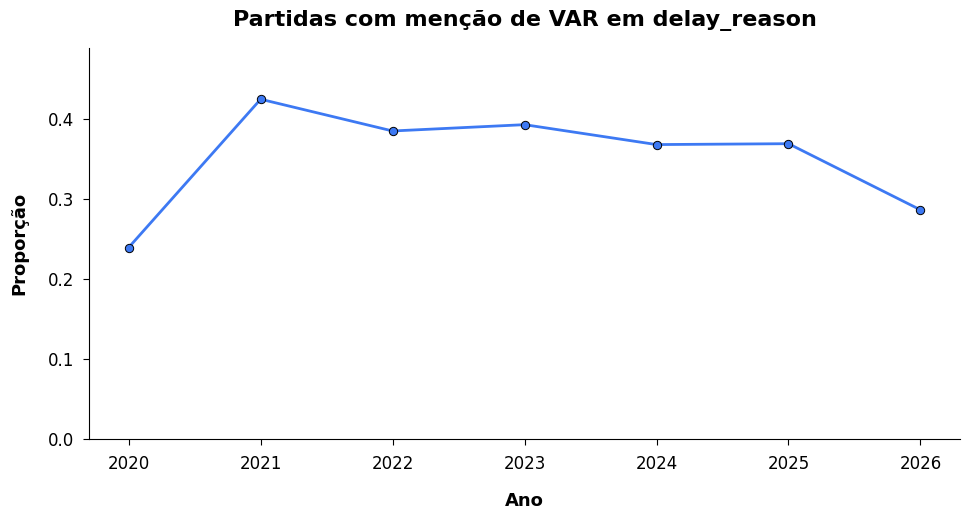

In [300]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(
    delay_var_by_year["year"],
    delay_var_by_year["pct_with_var_signal"],
    marker="o",
    color=PLOT_BLUE,
    markerfacecolor=PLOT_BLUE,
    markeredgecolor="black",
    markeredgewidth=0.7,
)
style_axis(ax, "Partidas com menção de VAR em delay_reason", "Ano", "Proporção")
style_lines(ax)
ax.set_ylim(0, max(0.05, delay_var_by_year["pct_with_var_signal"].max() * 1.15))
plt.tight_layout(pad=1.5)
save_plot(fig, "var_mentions_by_year.png")
plt.show()


In [301]:
var_examples = (
    delays[delays["var_used"]]
    .sort_values(["year", "round", "game_number"])
    [["year", "round", "home_team", "away_team", "arbitro_short", "var_signal", DELAY_TEXT_COLUMN]]
    .head(25)
)
var_examples


,year,round,home_team,away_team,arbitro_short,var_signal,delay_reason_clean
10,2020,1,Santos FC,Red Bull Bragantino,Ricardo Marques,"var, checagem",Não houve atraso no inicio e reinicio do jogo. foi cumprido a diretriz técnica operacional da cbf de entrada das equipes 05 (cinco) minutos antes do jogo para equipe local (15:55) e 04 (quatro) minutos antes do jogo ...
19,2020,1,Sport Recife,Ceará,Edina Alves,"var, checagem","Não houve atraso. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (20:55) e 4 (quatro) minutos antes do jogo para equipe visitante (20:56)..."
25,2020,1,Fortaleza Esporte Clube,Athletico Paranaense,Braulio da Silva,"var, checagem","Não houve atraso no início e reinício de jogo. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (18:55) e 4 (quatro) minutos antes do jogo ..."
74,2020,2,Vasco da Gama,Sport Recife,Rodolpho Toski,"var, revisao","Não houve atraso no início e reinício de jogo.foram acrescidos 2 minutos no primeiro tempo e 8 minutos no segundo tempo devido as substituições, reposição de bola em jogo, avaliação médica dos atletas supostamente le..."
83,2020,2,Atlético Mineiro,Corinthians,Wagner do Nascimento,var,"Não houve atraso no início e reinício da partida.acréscimos devido substituições,atendimento à atletas supostamente lesionados,reposição de bola em jogo e var.houve 01 minuto de silêncio em homenagem às vitimas do co..."
92,2020,2,Athletico Paranaense,Goiás,Diego Pombo,"var, checagem","Acréscimos no primeiro tempo devido a atendimento e retirada pela ambulância do atleta número 55 do athlético e também por checagens do var. acréscimos no segundo tempo devido a substituições, retirada de atletas sup..."
98,2020,2,Atlético,Flamengo,Luiz Flavio,"var, checagem","Não houve atrasos.acréscimos motivados por, atendimento médico, substituições, reposição de bola em jogo e checagem do var.informo que na relação nominal de atletas da equipe atletico cg, constava que o uniforme do g..."
120,2020,3,Fluminense,Internacional,Raphael Claus,"var, revisao","Não houve atraso no início e reinício da partida. houve acréscimos no primeiro e no segundo tempo de partida, devido as substituições, revisões do var, reposições de bola em jogo e atendimentos aos atletas supostamen..."
126,2020,3,Santos FC,Athletico Paranaense,Anderson Daronco,"var, checagem","Acréscimos de 4 minutos no primeiro tempo e 5 minutos no segundo tempo devido à paralisações, substituições, atendimento a atletas lesionados e checagem do var."
132,2020,3,Esporte Clube Bahia,Red Bull Bragantino,Felipe Fernandes,"var, checagem","Acréscimos devido as paralisações para retirada de atletas supostamente lesionados do campo de jogo, substituições e recuperação de tempo perdido por checagem do var.informo que foi respeitado um minuto de silêncio e..."


### **9.4 VAR por Time e Árbitro**

Para times: contagem sobre partidas em que o time aparece como mandante ou visitante — o mesmo jogo é contado para ambos. Para árbitros: contagem sobre as partidas apitadas. Em ambos os casos, `var_used` indica presença de sinal textual de VAR no campo de atraso, não validação externa do protocolo.


In [302]:
def most_common_non_empty(values: pd.Series) -> str:
    cleaned = values.astype(str).str.strip()
    cleaned = cleaned[cleaned.ne("")]
    if cleaned.empty:
        return ""
    return cleaned.value_counts().idxmax()

delay_home_games = delays.rename(columns={"home_team": "team", "away_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "arbitro_short", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_away_games = delays.rename(columns={"away_team": "team", "home_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "arbitro_short", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_team_games = pd.concat([delay_home_games, delay_away_games], ignore_index=True)

delay_var_by_team = (
    delay_team_games.groupby("team")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_team["pct_with_var_signal"] = (
    delay_var_by_team["games_with_var_signal"] / delay_var_by_team["games"]
).round(4)
delay_var_by_team = delay_var_by_team.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_team.head(TOP_N_TEAMS)


,team,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Red Bull Bragantino,456,174,"var, checagem",0.3816
1,Flamengo,443,189,"var, checagem",0.4266
2,Corinthians,442,194,"var, checagem",0.4389
3,Fluminense,442,173,"var, checagem",0.3914
4,Palmeiras,426,196,"var, checagem",0.4601
5,Internacional,417,177,"var, checagem",0.4245
6,Athletico Paranaense,398,170,"var, checagem",0.4271
7,São Paulo,396,207,"var, checagem",0.5227
8,Atlético Mineiro,396,146,"var, checagem",0.3687
9,Fortaleza Esporte Clube,368,158,"var, checagem",0.4293


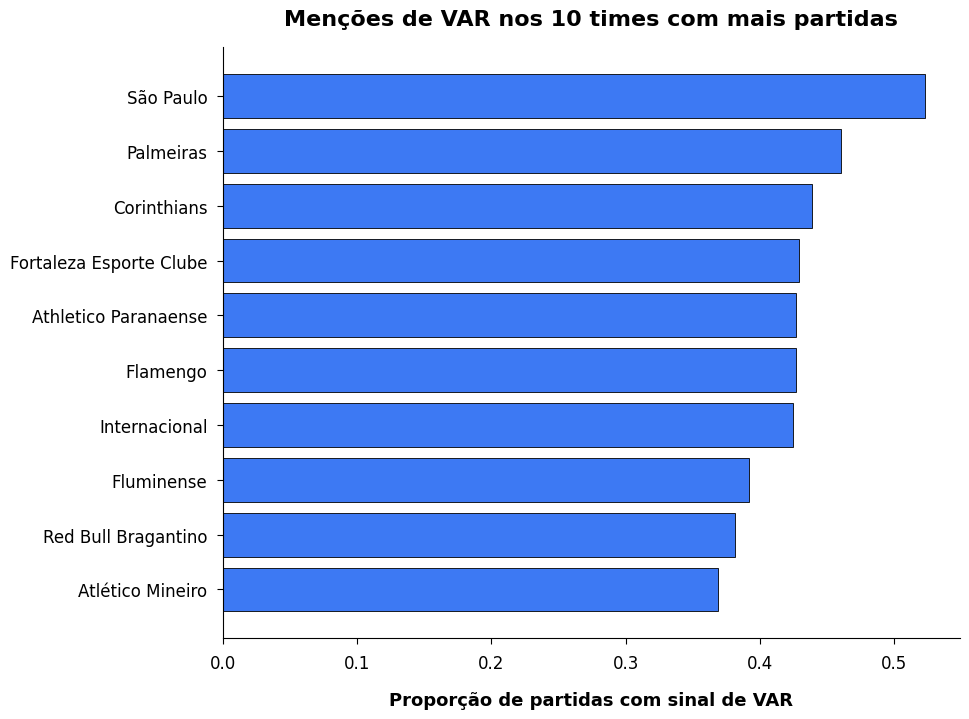

In [303]:
top_var_teams = delay_var_by_team.head(TOP_N_TEAMS).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(top_var_teams["team"], top_var_teams["pct_with_var_signal"], color=PLOT_BLUE, edgecolor="black", linewidth=0.6)
style_axis(ax, f"Menções de VAR nos {TOP_N_TEAMS} times com mais partidas", "Proporção de partidas com sinal de VAR", "")
plt.tight_layout(pad=1.5)
save_plot(fig, "var_mentions_by_team.png")
plt.show()


In [304]:
delay_var_by_referee = (
    delays.groupby(["arbitro", "arbitro_short"])
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_referee["pct_with_var_signal"] = (
    delay_var_by_referee["games_with_var_signal"] / delay_var_by_referee["games"]
).round(4)
delay_var_by_referee = delay_var_by_referee.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_referee.head(TOP_N_REFEREES)


,arbitro,arbitro_short,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Anderson Daronco,Anderson Daronco,255,83,"var, checagem",0.3255
1,Raphael Claus,Raphael Claus,243,80,"var, checagem",0.3292
2,Ramon Abatti Abel,Ramon Abatti,233,102,"var, checagem",0.4378
3,Wilton Pereira Sampaio,Wilton Pereira,223,103,"var, checagem",0.4619
4,Braulio da Silva Machado,Braulio da Silva,222,131,"var, checagem",0.5901
5,Flavio Rodrigues de Souza,Flavio Rodrigues,217,94,"var, checagem",0.4332
6,Bruno Arleu de Araujo,Bruno Arleu,205,87,"var, checagem",0.4244
7,Savio Pereira Sampaio,Savio Pereira,190,80,"var, checagem",0.4211
8,Marcelo de Lima Henrique,Marcelo de Lima,175,67,"var, checagem",0.3829
9,Wagner do Nascimento Magalhaes,Wagner do Nascimento,165,59,"var, checagem",0.3576


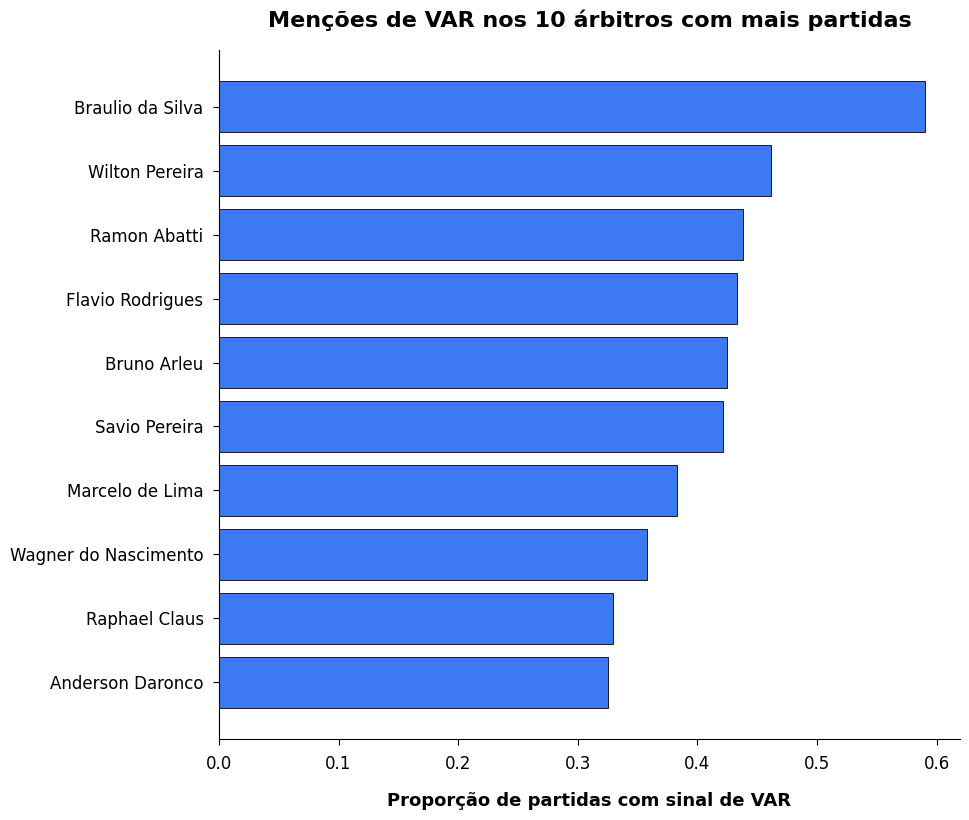

In [305]:
top_var_referees = delay_var_by_referee.head(TOP_N_REFEREES).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 8.5))
ax.barh(top_var_referees["arbitro_short"], top_var_referees["pct_with_var_signal"], color=PLOT_BLUE, edgecolor="black", linewidth=0.6)
style_axis(ax, f"Menções de VAR nos {TOP_N_REFEREES} árbitros com mais partidas", "Proporção de partidas com sinal de VAR", "")
plt.tight_layout(pad=1.5)
save_plot(fig, "var_mentions_by_referee.png")
plt.show()


## **10. Salvamento dos Artefatos**

Arquivos gerados em `data/processed/semantic_reasons/card_reasons/`:

- `card_reasons_with_labels.csv` — dataset completo com grupo semântico por cartão
- `card_reason_group_summary.csv` — distribuição de eventos por grupo
- `card_reason_group_quality.csv` — score médio, p10 e margem por grupo
- `card_reason_label_audit_terms.csv` — auditoria por texto único
- `card_reason_label_audit_clusters.csv` — auditoria por cluster BERTopic
- `card_reason_label_audit_outliers.csv` — auditoria dos outliers HDBSCAN

Arquivos gerados em `data/processed/semantic_reasons/delay_reasons/` mantêm a análise de VAR.


In [306]:
outros_audit = (
    cards[cards["card_reason_group"].eq("Outros")]
    .groupby(CARD_TEXT_COLUMN)
    .size()
    .reset_index(name="n_events")
    .sort_values("n_events", ascending=False)
)

card_topic_summary_path = CARD_OUTPUT_DIR / "card_bertopic_topic_summary.csv"
card_topic_examples_path = CARD_OUTPUT_DIR / "card_bertopic_topic_examples.csv"
card_unique_topics_path = CARD_OUTPUT_DIR / "card_reason_unique_topics_labels.csv"
card_labeled_path = CARD_OUTPUT_DIR / "card_reasons_with_labels.csv"
card_group_summary_path = CARD_OUTPUT_DIR / "card_reason_group_summary.csv"
card_group_quality_path = CARD_OUTPUT_DIR / "card_reason_group_quality.csv"
card_group_by_year_path = CARD_OUTPUT_DIR / "card_reason_group_by_year.csv"
card_group_by_type_path = CARD_OUTPUT_DIR / "card_reason_group_by_card_type.csv"
card_reason_by_team_path = CARD_OUTPUT_DIR / "card_reason_by_team.csv"
card_reason_top_by_team_path = CARD_OUTPUT_DIR / "card_reason_top_by_team.csv"
card_reason_by_referee_path = CARD_OUTPUT_DIR / "card_reason_by_referee.csv"
card_reason_top_by_referee_path = CARD_OUTPUT_DIR / "card_reason_top_by_referee.csv"
card_label_audit_terms_path = CARD_OUTPUT_DIR / "card_reason_label_audit_terms.csv"
card_label_audit_clusters_path = CARD_OUTPUT_DIR / "card_reason_label_audit_clusters.csv"
card_label_audit_outliers_path = CARD_OUTPUT_DIR / "card_reason_label_audit_outliers.csv"
outros_audit_path = CARD_OUTPUT_DIR / "card_reason_outros_audit.csv"

delay_topic_summary_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_summary.csv"
delay_topic_examples_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_examples.csv"
delay_unique_topics_path = DELAY_OUTPUT_DIR / "delay_reason_unique_topics.csv"
delay_labeled_path = DELAY_OUTPUT_DIR / "delay_reasons_with_var.csv"
delay_var_by_year_path = DELAY_OUTPUT_DIR / "delay_var_by_year.csv"
delay_var_by_team_path = DELAY_OUTPUT_DIR / "delay_var_by_team.csv"
delay_var_by_referee_path = DELAY_OUTPUT_DIR / "delay_var_by_referee.csv"

manual_taxonomy.to_csv(MANUAL_TAXONOMY_PATH, index=False)
manual_cluster_labels.to_csv(MANUAL_CLUSTER_LABELS_PATH, index=False)
manual_outlier_labels.to_csv(MANUAL_OUTLIER_LABELS_PATH, index=False)
card_topic_summary.to_csv(card_topic_summary_path, index=False)
card_topic_examples.to_csv(card_topic_examples_path, index=False)
card_text_counts.to_csv(card_unique_topics_path, index=False)
cards.to_csv(card_labeled_path, index=False)
card_group_summary.to_csv(card_group_summary_path, index=False)
card_group_quality.to_csv(card_group_quality_path, index=False)
card_group_by_year.to_csv(card_group_by_year_path)
card_group_by_type.to_csv(card_group_by_type_path)
card_reason_by_team.to_csv(card_reason_by_team_path, index=False)
card_reason_top_by_team.to_csv(card_reason_top_by_team_path, index=False)
card_reason_by_referee.to_csv(card_reason_by_referee_path, index=False)
card_reason_top_by_referee.to_csv(card_reason_top_by_referee_path, index=False)
card_reason_label_audit_terms.to_csv(card_label_audit_terms_path, index=False)
card_reason_label_audit_clusters.to_csv(card_label_audit_clusters_path, index=False)
card_reason_label_audit_outliers.to_csv(card_label_audit_outliers_path, index=False)
outros_audit.to_csv(outros_audit_path, index=False)

delay_topic_summary.to_csv(delay_topic_summary_path, index=False)
delay_topic_examples.to_csv(delay_topic_examples_path, index=False)
delay_text_counts.to_csv(delay_unique_topics_path, index=False)
delays.to_csv(delay_labeled_path, index=False)
delay_var_by_year.to_csv(delay_var_by_year_path, index=False)
delay_var_by_team.to_csv(delay_var_by_team_path, index=False)
delay_var_by_referee.to_csv(delay_var_by_referee_path, index=False)

output_paths = [
    MANUAL_TAXONOMY_PATH,
    MANUAL_CLUSTER_LABELS_PATH,
    MANUAL_OUTLIER_LABELS_PATH,
    card_topic_summary_path,
    card_topic_examples_path,
    card_unique_topics_path,
    card_labeled_path,
    card_group_summary_path,
    card_group_quality_path,
    card_group_by_year_path,
    card_group_by_type_path,
    card_reason_by_team_path,
    card_reason_top_by_team_path,
    card_reason_by_referee_path,
    card_reason_top_by_referee_path,
    card_label_audit_terms_path,
    card_label_audit_clusters_path,
    card_label_audit_outliers_path,
    outros_audit_path,
    delay_topic_summary_path,
    delay_topic_examples_path,
    delay_unique_topics_path,
    delay_labeled_path,
    delay_var_by_year_path,
    delay_var_by_team_path,
    delay_var_by_referee_path,
]

print("Arquivos salvos:")
for output_path in output_paths:
    print(f"  {output_path}")


Arquivos salvos:
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_taxonomy.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_manual_cluster_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_manual_outlier_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_examples.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_unique_topics_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reasons_with_labels.csv
  /Users/g